In [6]:
#!/usr/bin/env python
# coding: utf-8

# # Tc: три представления признаков и GridSearchCV
# 
# Автономный notebook для предсказания температуры Кюри Tc (K): один входной
# Excel-файл, обязательные размер кристаллитов и температура отжига (магнитное
# поле не используется), сравнение Stoichiometry, XenonPy и их объединения
# на одних и тех же nested group CV-разбиениях.
# 
# Гиперпараметры и число химических признаков выбираются GridSearchCV только
# внутри inner-folds по заранее заданной сетке конфигураций.
# 
# В этой версии входные признаки стандартизируются внутри каждого train-fold;
# при NORMALIZE_TARGET = False целевая переменная используется в исходных
# единицах без log1p.
# 
# ## Перед запуском
# 
# Используйте kernel `Python (MCE XenonPy)` с NumPy 1.26.4. Сначала при необходимости задайте `SEARCH_PROFILE = "quick"`; для итогового расчёта оставьте `standard`.
# 
# ## Ограничение Числа Потоков
# 

# In[2]:


# Эту часть необходимо выполнить до импорта NumPy.
# Если NumPy уже импортирован, перезапустите kernel.

import os

os.environ["OMP_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"
os.environ["NUMEXPR_NUM_THREADS"] = "1"
os.environ["VECLIB_MAXIMUM_THREADS"] = "1"


# При необходимости установите пакеты в среде mce_xenonpy:
# 
# %pip install "numpy==1.26.4"
# %pip install "xenonpy==0.6.7" rdkit
# %pip install pandas matplotlib scikit-learn openpyxl joblib
# %pip install pymatgen xgboost catboost plotly
# 
# 
# ## Импорт


# In[3]:


import gc
import json
import re
import sys
import textwrap
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from pymatgen.core import Composition

from xenonpy.datatools import preset
from xenonpy.descriptor.compositions import (
    MaxPooling,
    MinPooling,
    WeightedAverage,
    WeightedSum,
    WeightedVariance,
)

from sklearn.base import clone
from sklearn.compose import (
    ColumnTransformer,
    TransformedTargetRegressor,
)
from sklearn.ensemble import ExtraTreesRegressor, RandomForestRegressor
from sklearn.feature_selection import SelectFromModel
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import HuberRegressor, Ridge
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)
from sklearn.model_selection import GridSearchCV
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler

try:
    from xgboost import XGBRegressor
except ImportError:
    XGBRegressor = None

try:
    from catboost import CatBoostRegressor
except ImportError:
    CatBoostRegressor = None


warnings.filterwarnings("ignore", category=SyntaxWarning)


try:
    from IPython.display import display
except ImportError:

    def display(value):
        print(value)


plt.rcParams.update({
    "font.family": "DejaVu Serif",
    "font.size": 10,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "figure.dpi": 130,
})


# Единая, различимая при дальтонизме палитра для всех рисунков статьи.
PUBLICATION_COLORS = {
    "Stoichiometry": "#0072B2",
    "XenonPy": "#D55E00",
    "Combined": "#009E73",
    "training": "#7A7A7A",
    "reference": "#222222",
}

# Точный размер отдельных сравнительных рисунков для статьи.
FIGURE_SIZE_CM = 8.0
FIGURE_SIZE_INCH = FIGURE_SIZE_CM / 2.54


# ## Настройки
# 

# In[5]:


INPUT_FILE = Path(
    r"/Users/artemykagramanian/Desktop/ампермагнит/MCE + ML/итоговые датасеты/DB_mc_broad_synth.xlsx"
)

INPUT_SHEET = "1"

OUTPUT_DIRECTORY = Path(
    r"/Users/artemykagramanian/Desktop/ампермагнит/MCE + ML/ipynb and results FMM version/Tc_Three_Feature_Sets_GridSearch_results"
)


# ------------------------- данные ------------------------------------

TARGET_PROPERTY = "Tc (K)"
TARGET_COLUMN = "target_tc_K"

OXYGEN_REFERENCE = 3.0
STOICHIOMETRY_DECIMALS = 12

# Tc всегда положительна, поэтому модуль не нужен.
TARGET_AS_ABSOLUTE = False

# Выбросы помечаются, но по умолчанию не удаляются.
REMOVE_TARGET_OUTLIERS = False
MIN_VALUES_FOR_IQR = 8


# ------------------------- XenonPy -----------------------------------

XENONPY_BATCH_SIZE = 10


# -------------------------- модели -----------------------------------

RANDOM_STATE = 42

OUTER_SPLITS = 5
INNER_SPLITS = 3

# На Windows сначала оставьте 1.
GRID_N_JOBS = 1

# quick — проверочный запуск;
# standard — итоговый расчёт.
SEARCH_PROFILE = "standard"
MODELS_TO_RUN = ["Ridge", "KNN", "Random Forest", "XGBoost", "CatBoost"]

# Устойчивая функция потерь Huber для CatBoost и XGBoost (pseudo-Huber).
# Порог задан в долях стандартного отклонения Tc обучающей части:
# ошибки меньше HUBER_DELTA_SIGMA·σ считаются как в обычной MSE,
# более крупные учитываются линейно, поэтому далёкие от остальных точки
# тянут модель слабее. По пилоту на Tc значение 2.0 не ухудшает R²
# (значения 0.3–0.75 заметно ухудшали из-за слишком медленного обучения).
HUBER_DELTA_SIGMA = 2.0

# True: вместо Ridge используется линейная HuberRegressor (с L2-штрафом).
# По пилоту на Tc она не лучше Ridge, поэтому по умолчанию выключено.
RIDGE_USE_HUBER = False

# Стандартизация выполняется внутри каждого train-fold и предотвращает
# численную неустойчивость Ridge при признаках разных масштабов.
NORMALIZE_INPUTS = True
# False: целевая переменная используется без преобразований.
# True: внутри train-fold применяется log1p и стандартизация.
NORMALIZE_TARGET = False

# Если среда ограничена по времени, временно используйте quick.
# Число химических признаков также подбирается внутри inner CV.
# Для объединённого набора предусмотрен расширенный диапазон.
QUICK_SELECTED_FEATURES = [5, 10, 20, 50]
STANDARD_SELECTED_FEATURES = [
    5, 10, 15, 20, 30, 50, 75, 100, 150, 200, 250,
]

SELECTOR_TREES = 250
SELECTOR_MAX_DEPTH = 7
SELECTOR_MIN_SAMPLES_LEAF = 3

OVERFIT_R2_GAP_THRESHOLD = 0.25
BOOTSTRAP_REPEATS = 1000


# ## Выходные Папки
# 

# In[7]:


XENONPY_CHECKPOINT_DIRECTORY = (
    OUTPUT_DIRECTORY / "xenonpy_checkpoints"
)

FIGURE_DIRECTORY = (
    OUTPUT_DIRECTORY / "figures"
)

MODEL_DIRECTORY = (
    OUTPUT_DIRECTORY / "models"
)

TABLE_DIRECTORY = (
    OUTPUT_DIRECTORY / "tables"
)

PIPELINE_CACHE_DIRECTORY = (
    OUTPUT_DIRECTORY / "pipeline_cache"
)


def prepare_directories():
    """Создаёт папки для всех результатов."""

    for directory in [
        OUTPUT_DIRECTORY,
        XENONPY_CHECKPOINT_DIRECTORY,
        FIGURE_DIRECTORY,
        MODEL_DIRECTORY,
        TABLE_DIRECTORY,
        PIPELINE_CACHE_DIRECTORY,
    ]:
        directory.mkdir(
            parents=True,
            exist_ok=True,
        )

# функции

In [2]:
# ## Служебные Функции
# 

# In[9]:


def normalize_property_name(value):
    """Удаляет пробелы и приводит название свойства к нижнему регистру."""

    return re.sub(
        r"\s+",
        "",
        str(value).strip(),
    ).casefold()


def numeric_from_mixed(value):
    """
    Извлекает число из значений:
    5, 5.0, '5 T', '45 nm', '5,0 Тл'.
    """

    if pd.isna(value):
        return np.nan

    if isinstance(
        value,
        (int, float, np.integer, np.floating),
    ):
        return float(value)

    text = (
        str(value)
        .strip()
        .replace("−", "-")
        .replace(",", ".")
    )

    match = re.search(
        r"[-+]?(?:\d+(?:\.\d*)?|\.\d+)(?:[eE][-+]?\d+)?",
        text,
    )

    if match is None:
        return np.nan

    return float(match.group(0))


def clean_formula(formula):
    """Приводит строку химической формулы к единому виду."""

    if pd.isna(formula):
        return None

    text = (
        str(formula)
        .strip()
        .replace(" ", "")
        .replace("−", "-")
        .replace("–", "-")
        .replace(",", ".")
    )

    if not text:
        return None

    return text


def parse_formula(formula):
    """Преобразует химическую формулу в словарь состава."""

    cleaned = clean_formula(formula)

    if cleaned is None:
        raise ValueError("пустая химическая формула")

    try:
        composition = Composition(
            cleaned
        ).get_el_amt_dict()

    except Exception as error:
        raise ValueError(
            f"ошибка разбора формулы: {error}"
        ) from error

    result = {}

    for element, amount in composition.items():
        amount = float(amount)

        if not np.isfinite(amount) or amount <= 0:
            raise ValueError(
                f"некорректный коэффициент у {element}: {amount}"
            )

        result[str(element)] = amount

    if not result:
        raise ValueError("пустой состав после разбора")

    return result


def contains_manganese(composition):
    """Проверяет наличие элемента Mn."""

    manganese_amount = float(
        composition.get("Mn", 0.0)
    )

    return (
        np.isfinite(manganese_amount)
        and manganese_amount > 0
    )


def normalize_composition_to_o3(
    composition,
    oxygen_reference=OXYGEN_REFERENCE,
):
    """Нормирует все коэффициенты к O = 3."""

    oxygen_amount = float(
        composition.get("O", np.nan)
    )

    if (
        not np.isfinite(oxygen_amount)
        or oxygen_amount <= 0
    ):
        raise ValueError(
            "в составе отсутствует положительный коэффициент кислорода"
        )

    scale_factor = (
        float(oxygen_reference)
        / oxygen_amount
    )

    normalized = {}

    for element, amount in composition.items():
        normalized_amount = (
            float(amount)
            * scale_factor
        )

        nearest_integer = round(
            normalized_amount
        )

        if np.isclose(
            normalized_amount,
            nearest_integer,
            atol=10 ** (-STOICHIOMETRY_DECIMALS),
            rtol=0.0,
        ):
            normalized_amount = float(
                nearest_integer
            )
        else:
            normalized_amount = float(
                round(
                    normalized_amount,
                    STOICHIOMETRY_DECIMALS,
                )
            )

        if normalized_amount > 0:
            normalized[str(element)] = (
                normalized_amount
            )

    normalized["O"] = float(
        oxygen_reference
    )

    return normalized


def format_amount(
    amount,
    omit_one=True,
):
    """Форматирует стехиометрический коэффициент."""

    amount = float(amount)

    if (
        omit_one
        and np.isclose(
            amount,
            1.0,
            atol=1e-12,
            rtol=0.0,
        )
    ):
        return ""

    nearest_integer = round(amount)

    if np.isclose(
        amount,
        nearest_integer,
        atol=1e-12,
        rtol=0.0,
    ):
        return str(
            int(nearest_integer)
        )

    return np.format_float_positional(
        amount,
        precision=STOICHIOMETRY_DECIMALS,
        unique=True,
        trim="-",
    )


def composition_to_formula(composition):
    """
    Формирует однозначную нормированную формулу.
    Кислород записывается последним.
    """

    elements = sorted(
        element
        for element in composition
        if element != "O"
    )

    if "O" in composition:
        elements.append("O")

    formula_parts = []

    for element in elements:
        amount_text = format_amount(
            composition[element],
            omit_one=(element != "O"),
        )

        formula_parts.append(
            f"{element}{amount_text}"
        )

    return "".join(formula_parts)


def composition_key(composition):
    """Канонический ключ состава для групповой валидации."""

    return "|".join(
        (
            f"{element}:"
            f"{float(composition[element]):.12g}"
        )
        for element in sorted(composition)
    )


def element_set_key(composition):
    """Ключ набора химических элементов."""

    return "-".join(
        sorted(composition)
    )


# ## Чтение Единственного Входного Файла
# 

# In[11]:


def load_source_data():
    """Читает единственный входной Excel-файл."""

    if not INPUT_FILE.exists():
        raise FileNotFoundError(
            "Исходный файл не найден:\n"
            f"{INPUT_FILE}\n\n"
            "Исправьте INPUT_FILE в разделе НАСТРОЙКИ."
        )

    dataframe = pd.read_excel(
        INPUT_FILE,
        sheet_name=INPUT_SHEET,
    )

    dataframe.columns = (
        dataframe.columns
        .astype(str)
        .str.strip()
    )

    required_columns = {
        "Compound",
        "Property",
        "Value",
        "D_crystalite [nm]",
    }

    missing_columns = (
        required_columns
        .difference(dataframe.columns)
    )

    if missing_columns:
        raise KeyError(
            "В исходном Excel отсутствуют столбцы: "
            f"{sorted(missing_columns)}"
        )

    dataframe = dataframe.copy()

    # Номер строки в Excel с учётом строки заголовков.
    dataframe["Source_row"] = (
        np.arange(len(dataframe)) + 2
    )

    print("Python:", sys.executable)
    print("NumPy:", np.__version__)
    print("Pandas:", pd.__version__)
    print("Входной файл:", INPUT_FILE)
    print("Лист Excel:", INPUT_SHEET)
    print("Строк в исходном файле:", len(dataframe))

    return dataframe


# ## Подготовка Общей Ml-Выборки
# 

# In[13]:


def mark_target_outliers(dataframe):
    """
    Помечает выбросы Tc по правилу 1.5·IQR (по всей выборке).

    Автоматически они не удаляются, если
    REMOVE_TARGET_OUTLIERS = False.
    """

    result = dataframe.copy()

    result["Is_target_outlier"] = False

    values = result[TARGET_COLUMN]

    if len(values) >= MIN_VALUES_FOR_IQR:
        q1 = values.quantile(0.25)
        q3 = values.quantile(0.75)
        iqr = q3 - q1

        if np.isfinite(iqr) and iqr > 0:
            result["Is_target_outlier"] = ~values.between(
                q1 - 1.5 * iqr,
                q3 + 1.5 * iqr,
                inclusive="both",
            )

    return result


def prepare_ml_dataset(source):
    """
    Фильтрует ME, оставляет Mn, нормирует к O3
    и создаёт стехиометрические признаки comp_*.
    """

    target_property_clean = (
        normalize_property_name(
            TARGET_PROPERTY
        )
    )

    property_clean = (
        source["Property"]
        .map(normalize_property_name)
    )

    selected = source.loc[
        property_clean.eq(
            target_property_clean
        )
    ].copy()

    selected["Target_numeric"] = (
        selected["Value"]
        .map(numeric_from_mixed)
    )

    selected["Size_numeric"] = (
        selected["D_crystalite [nm]"]
        .map(numeric_from_mixed)
    )

    if TARGET_AS_ABSOLUTE:
        selected["Target_numeric"] = (
            selected["Target_numeric"].abs()
        )

    valid_rows = []
    rejected_rows = []

    for _, row in selected.iterrows():

        rejection_reason = None
        composition = None
        normalized_composition = None

        try:
            composition = parse_formula(
                row["Compound"]
            )

            if not contains_manganese(
                composition
            ):
                raise ValueError(
                    "соединение не содержит Mn"
                )

            normalized_composition = (
                normalize_composition_to_o3(
                    composition
                )
            )

        except ValueError as error:
            rejection_reason = str(error)

        target_value = row["Target_numeric"]
        size_value = row["Size_numeric"]

        if rejection_reason is None:
            if (
                not np.isfinite(target_value)
                or target_value <= 0
            ):
                rejection_reason = (
                    "целевая величина отсутствует "
                    "или неположительна"
                )

        if rejection_reason is None:
            if (
                not np.isfinite(size_value)
                or size_value <= 0
            ):
                rejection_reason = (
                    "размер кристаллитов отсутствует "
                    "или неположителен"
                )

        if rejection_reason is not None:
            rejected_rows.append({
                "Source_row": row["Source_row"],
                "Compound": row["Compound"],
                "Value": row["Value"],
                "D_crystalite [nm]": (
                    row["D_crystalite [nm]"]
                ),
                "Rejection_reason": rejection_reason,
            })
            continue

        valid_rows.append({
            "Source_row": int(row["Source_row"]),
            "original_formula": str(
                row["Compound"]
            ).strip(),
            "normalized_formula_O3": (
                composition_to_formula(
                    normalized_composition
                )
            ),
            "composition_key": (
                composition_key(
                    normalized_composition
                )
            ),
            "element_set_key": (
                element_set_key(
                    normalized_composition
                )
            ),
            "composition": (
                normalized_composition
            ),
            "crystallite_size_nm": float(
                size_value
            ),
            TARGET_COLUMN: float(
                target_value
            ),

            "T_final_C": pd.to_numeric(
                row.get("T_final_C"), errors="coerce"
            ),
            "Synthesis_route": row.get("Synthesis_route"),
        })

    valid = pd.DataFrame(
        valid_rows
    )

    rejected = pd.DataFrame(
        rejected_rows
    )

    if valid.empty:
        raise ValueError(
            "После фильтрации не осталось "
            "ни одной валидной строки."
        )

    elements = sorted({
        element
        for composition in valid["composition"]
        for element in composition
        if element != "O"
    })

    stoichiometry_features = []

    for element in elements:
        feature_name = f"comp_{element}"

        valid[feature_name] = (
            valid["composition"]
            .map(
                lambda current, element=element:
                current.get(element, 0.0)
            )
        )

        stoichiometry_features.append(
            feature_name
        )

    aggregate_keys = [
        "composition_key",
        "crystallite_size_nm",
    ]

    metadata = (
        valid
        .groupby(
            aggregate_keys,
            sort=True,
        )
        .agg(
            original_formula=(
                "original_formula",
                "first",
            ),
            normalized_formula_O3=(
                "normalized_formula_O3",
                "first",
            ),
            element_set_key=(
                "element_set_key",
                "first",
            ),
            **{
                TARGET_COLUMN: (
                    TARGET_COLUMN,
                    "median",
                )
            },
            target_min=(
                TARGET_COLUMN,
                "min",
            ),
            target_max=(
                TARGET_COLUMN,
                "max",
            ),
            n_measurements=(
                TARGET_COLUMN,
                "size",
            ),

            T_final_C=("T_final_C", "median"),

            Synthesis_route=("Synthesis_route", "first"),
        )
    )

    feature_table = (
        valid
        .groupby(
            aggregate_keys,
            sort=True,
        )[stoichiometry_features]
        .first()
    )

    ml_dataset = (
        metadata
        .join(feature_table)
        .reset_index()
    )

    global PROCESS_FEATURES, PROCESS_SELECTABLE_FEATURES
    PROCESS_FEATURES = []
    PROCESS_SELECTABLE_FEATURES = []
    if USE_PROCESS_FEATURES:
        ml_dataset["process_T_final_C"] = ml_dataset["T_final_C"]
        PROCESS_FEATURES = ["process_T_final_C"]
        route = ml_dataset["Synthesis_route"].fillna("unknown")
        known = ["sol_gel", "solid_state", "combustion", "unknown"]
        route = route.where(route.isin(known), "other_route")
        for name in known + ["other_route"]:
            column = f"process_route_{name}"
            ml_dataset[column] = (route == name).astype(float)
            PROCESS_SELECTABLE_FEATURES.append(column)

    ml_dataset = mark_target_outliers(
        ml_dataset
    )

    if REMOVE_TARGET_OUTLIERS:
        ml_dataset = ml_dataset.loc[
            ~ml_dataset["Is_target_outlier"]
        ].copy()

    ml_dataset = (
        ml_dataset
        .reset_index(drop=True)
    )

    unique_compositions = (
        valid[
            [
                "composition_key",
                "normalized_formula_O3",
                "composition",
            ]
        ]
        .drop_duplicates(
            subset="composition_key"
        )
        .reset_index(drop=True)
    )

    audit = pd.DataFrame([
        {
            "Stage": "Все строки исходного файла",
            "Rows": len(source),
        },
        {
            "Stage": f"Строки {TARGET_PROPERTY}",
            "Rows": len(selected),
        },
        {
            "Stage": "Валидные Mn-измерения",
            "Rows": len(valid),
        },
        {
            "Stage": "Отклонённые строки",
            "Rows": len(rejected),
        },
        {
            "Stage": "После агрегации",
            "Rows": len(ml_dataset),
        },
        {
            "Stage": "Уникальные составы",
            "Rows": len(unique_compositions),
        },
        {
            "Stage": "Помеченные выбросы",
            "Rows": int(
                ml_dataset[
                    "Is_target_outlier"
                ].sum()
            ),
        },
    ])

    return (
        valid,
        ml_dataset,
        unique_compositions,
        stoichiometry_features,
        rejected,
        audit,
    )


# ## Проверка Xenonpy
# 

# In[15]:


def check_xenonpy_database():
    """Проверяет локальную базу свойств элементов."""

    try:
        elements_data = (
            preset.elements_completed
        )

        print(
            "База XenonPy elements_completed:",
            elements_data.shape,
        )

    except RuntimeError as error:
        print(
            "\nБаза XenonPy отсутствует.\n"
            "Один раз выполните:\n\n"
            "from xenonpy.datatools import preset\n"
            "preset.sync('elements_completed')\n"
        )

        raise error


# ## Расчёт Xenonpy-Дескрипторов
# 

# In[17]:


def calculate_in_batches(
    calculator,
    calculator_name,
    compositions,
):
    """Рассчитывает дескрипторы небольшими пакетами."""

    calculator_directory = (
        XENONPY_CHECKPOINT_DIRECTORY
        / calculator_name
    )

    calculator_directory.mkdir(
        parents=True,
        exist_ok=True,
    )

    results = []
    number_of_compositions = len(
        compositions
    )

    print("\n" + "=" * 72)
    print("XenonPy:", calculator_name)
    print(
        "Количество составов:",
        number_of_compositions,
    )

    for start in range(
        0,
        number_of_compositions,
        XENONPY_BATCH_SIZE,
    ):
        stop = min(
            start + XENONPY_BATCH_SIZE,
            number_of_compositions,
        )

        print(
            f"{calculator_name}: "
            f"пакет {start}:{stop}",
            flush=True,
        )

        current_compositions = (
            compositions
            .iloc[start:stop]
            .tolist()
        )

        current_result = (
            calculator.transform(
                current_compositions
            )
        )

        if not isinstance(
            current_result,
            pd.DataFrame,
        ):
            current_result = pd.DataFrame(
                current_result,
                columns=calculator.feature_labels,
            )

        current_result = (
            current_result
            .reset_index(drop=True)
            .replace(
                [np.inf, -np.inf],
                np.nan,
            )
        )

        checkpoint_file = (
            calculator_directory
            / (
                f"{calculator_name}_"
                f"{start:04d}_{stop:04d}.csv"
            )
        )

        current_result.to_csv(
            checkpoint_file,
            index=False,
            encoding="utf-8-sig",
        )

        results.append(
            current_result
        )

        del current_compositions
        gc.collect()

    complete_result = pd.concat(
        results,
        ignore_index=True,
    )

    print(
        f"{calculator_name}: "
        f"{complete_result.shape}"
    )

    return complete_result


def calculate_xenonpy_descriptors(
    unique_compositions,
):
    """Рассчитывает пять семейств дескрипторов."""

    calculators = {
        "average": WeightedAverage(
            n_jobs=1,
            on_errors="nan",
            return_type="df",
        ),
        "sum": WeightedSum(
            n_jobs=1,
            on_errors="nan",
            return_type="df",
        ),
        "variance": WeightedVariance(
            n_jobs=1,
            on_errors="nan",
            return_type="df",
        ),
        "maximum": MaxPooling(
            n_jobs=1,
            on_errors="nan",
            return_type="df",
        ),
        "minimum": MinPooling(
            n_jobs=1,
            on_errors="nan",
            return_type="df",
        ),
    }

    descriptor_parts = []

    for calculator_name, calculator in calculators.items():

        current_descriptors = (
            calculate_in_batches(
                calculator=calculator,
                calculator_name=calculator_name,
                compositions=(
                    unique_compositions[
                        "composition"
                    ]
                ),
            )
        )

        current_descriptors = (
            current_descriptors.add_prefix(
                f"xenonpy_{calculator_name}__"
            )
        )

        descriptor_parts.append(
            current_descriptors
        )

    descriptors = pd.concat(
        descriptor_parts,
        axis=1,
    )

    descriptors = descriptors.replace(
        [np.inf, -np.inf],
        np.nan,
    )

    all_nan_columns = (
        descriptors.columns[
            descriptors.isna().all()
        ]
        .tolist()
    )

    constant_columns = (
        descriptors.columns[
            descriptors.nunique(
                dropna=True
            ) <= 1
        ]
        .tolist()
    )

    columns_to_remove = sorted(
        set(
            all_nan_columns
            + constant_columns
        )
    )

    descriptors = descriptors.drop(
        columns=columns_to_remove,
    )

    removed_descriptors = pd.DataFrame({
        "Descriptor": columns_to_remove,
        "Reason": [
            (
                "all_NaN"
                if column in all_nan_columns
                else "constant"
            )
            for column in columns_to_remove
        ],
    })

    descriptor_lookup = pd.concat(
        [
            unique_compositions[
                [
                    "composition_key",
                    "normalized_formula_O3",
                ]
            ].reset_index(drop=True),
            descriptors.reset_index(drop=True),
        ],
        axis=1,
    )

    xenonpy_features = sorted(
        column
        for column in descriptor_lookup.columns
        if column.startswith(
            "xenonpy_"
        )
    )

    if not xenonpy_features:
        raise ValueError(
            "После очистки не осталось "
            "XenonPy-дескрипторов."
        )

    print("\nРасчёт XenonPy завершён")
    print(
        "Итоговое количество признаков:",
        len(xenonpy_features),
    )
    print(
        "Удалено признаков:",
        len(columns_to_remove),
    )

    return (
        descriptor_lookup,
        xenonpy_features,
        removed_descriptors,
    )


# ## Групповые Разбиения
# 

# In[20]:


def make_balanced_group_splits(
    group_values,
    n_splits,
    seed,
):
    """
    Создаёт сбалансированные групповые фолды.

    Один химический состав не может одновременно
    находиться в train и test.
    """

    groups_array = np.asarray(
        pd.Series(
            group_values
        ).astype(str)
    )

    unique_groups, counts = np.unique(
        groups_array,
        return_counts=True,
    )

    if len(unique_groups) < 2:
        raise ValueError(
            "Требуются минимум две независимые группы."
        )

    n_splits = min(
        int(n_splits),
        len(unique_groups),
    )

    if n_splits < 2:
        raise ValueError(
            "Число фолдов должно быть не меньше двух."
        )

    rng = np.random.default_rng(seed)

    random_tie_break = rng.random(
        len(unique_groups)
    )

    order = np.lexsort(
        (
            random_tie_break,
            -counts,
        )
    )

    fold_groups = [
        []
        for _ in range(n_splits)
    ]

    fold_sizes = np.zeros(
        n_splits,
        dtype=int,
    )

    for position in order:
        fold = int(
            np.argmin(fold_sizes)
        )

        fold_groups[fold].append(
            unique_groups[position]
        )

        fold_sizes[fold] += (
            counts[position]
        )

    splits = []

    for test_groups in fold_groups:

        test_mask = np.isin(
            groups_array,
            test_groups,
        )

        train_index = np.flatnonzero(
            ~test_mask
        )

        test_index = np.flatnonzero(
            test_mask
        )

        if (
            len(train_index) == 0
            or len(test_index) == 0
        ):
            raise RuntimeError(
                "Получен пустой train или test."
            )

        assert set(
            groups_array[train_index]
        ).isdisjoint(
            set(groups_array[test_index])
        )

        splits.append(
            (
                train_index,
                test_index,
            )
        )

    return splits


# ## Метрики
# 

# In[22]:


def physical_predictions(
    estimator,
    X_values,
):
    """Возвращает неотрицательный прогноз."""

    predictions = np.asarray(
        estimator.predict(X_values),
        dtype=float,
    )

    return np.maximum(
        predictions,
        0.0,
    )


def physical_r2_scorer(
    estimator,
    X_values,
    y_true,
):
    """R² в исходных единицах Tc (K)."""

    predictions = physical_predictions(
        estimator,
        X_values,
    )

    return r2_score(
        np.asarray(
            y_true,
            dtype=float,
        ),
        predictions,
    )


def regression_metrics(
    y_true,
    y_pred,
):
    """Вычисляет R², MAE и RMSE."""

    actual = np.asarray(
        y_true,
        dtype=float,
    )

    predicted = np.asarray(
        y_pred,
        dtype=float,
    )

    return {
        "N": len(actual),
        "R2": (
            r2_score(
                actual,
                predicted,
            )
            if len(actual) > 1
            else np.nan
        ),
        "MAE": mean_absolute_error(
            actual,
            predicted,
        ),
        "RMSE": np.sqrt(
            mean_squared_error(
                actual,
                predicted,
            )
        ),
    }


def group_bootstrap_ci(
    predictions,
    repeats=BOOTSTRAP_REPEATS,
    seed=RANDOM_STATE,
):
    """
    Доверительные интервалы с пересэмплированием
    целых химических составов.
    """

    unique_groups = (
        predictions[
            "Composition_key"
        ]
        .drop_duplicates()
        .to_numpy()
    )

    rng = np.random.default_rng(seed)

    metric_values = {
        "R2": [],
        "MAE": [],
        "RMSE": [],
    }

    for _ in range(repeats):

        sampled_groups = rng.choice(
            unique_groups,
            size=len(unique_groups),
            replace=True,
        )

        sampled_parts = [
            predictions.loc[
                predictions[
                    "Composition_key"
                ].eq(group)
            ]
            for group in sampled_groups
        ]

        sampled = pd.concat(
            sampled_parts,
            ignore_index=True,
        )

        metrics = regression_metrics(
            sampled["Actual"],
            sampled["Predicted"],
        )

        for metric_name in metric_values:
            value = metrics[metric_name]

            if np.isfinite(value):
                metric_values[
                    metric_name
                ].append(value)

    result = {}

    for metric_name, values in metric_values.items():

        if values:
            result[
                f"{metric_name}_CI95_low"
            ] = float(
                np.quantile(
                    values,
                    0.025,
                )
            )

            result[
                f"{metric_name}_CI95_high"
            ] = float(
                np.quantile(
                    values,
                    0.975,
                )
            )
        else:
            result[
                f"{metric_name}_CI95_low"
            ] = np.nan

            result[
                f"{metric_name}_CI95_high"
            ] = np.nan

    return result


# ## Препроцессинг
# 

# In[24]:


REQUIRED_PHYSICAL_FEATURES = [
    "crystallite_size_nm",
]

USE_PROCESS_FEATURES = True
PROCESS_FEATURES = []  # заполняется в prepare_ml_dataset


def physical_input_features():
    """Размер кристаллитов + температура отжига (и пр. признаки процесса)."""
    return REQUIRED_PHYSICAL_FEATURES + list(PROCESS_FEATURES)


def scaler_step():
    """Возвращает стандартизацию или прозрачный шаг."""
    return StandardScaler() if NORMALIZE_INPUTS else "passthrough"


def selected_feature_candidates(number_of_features):
    """Допустимые числа химических признаков для nested GridSearch."""
    requested = (
        QUICK_SELECTED_FEATURES
        if SEARCH_PROFILE == "quick"
        else STANDARD_SELECTED_FEATURES
    )
    candidates = {
        min(int(value), int(number_of_features))
        for value in requested
        if int(value) > 0
    }
    # Полный набор всегда участвует как контрольный вариант без сокращения.
    candidates.add(int(number_of_features))
    return sorted(candidates)


def build_preprocessor(chemical_features):
    """
    Размер кристаллитов и температура отжига обрабатываются отдельной
    защищённой веткой.

    Отбор выполняется только для химических признаков и только внутри
    соответствующего train-fold. crystallite_size_nm и process_T_final_C
    всегда поступают в модель и никогда не удаляются selector-ом.
    """
    physical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
        ("scaler", scaler_step()),
    ])

    initial_number = max(selected_feature_candidates(len(chemical_features)))
    ranking_model = ExtraTreesRegressor(
        n_estimators=SELECTOR_TREES,
        max_depth=SELECTOR_MAX_DEPTH,
        min_samples_leaf=SELECTOR_MIN_SAMPLES_LEAF,
        max_features="sqrt",
        random_state=RANDOM_STATE,
        n_jobs=1,
    )

    chemical_pipeline = Pipeline([
        (
            "imputer",
            SimpleImputer(
                strategy="median",
                keep_empty_features=True,
            ),
        ),
        ("scaler", scaler_step()),
        (
            "selector",
            SelectFromModel(
                estimator=ranking_model,
                threshold=-np.inf,
                max_features=initial_number,
            ),
        ),
    ])

    return ColumnTransformer(
        transformers=[
            (
                "required_physical",
                physical_pipeline,
                physical_input_features(),
            ),
            (
                "chemical",
                chemical_pipeline,
                chemical_features,
            ),
        ],
        remainder="drop",
        verbose_feature_names_out=True,
    )


def wrap_target(regression_pipeline, standardize=False):
    """
    Настраивает преобразование target внутри каждого train-fold.

    standardize=True (только при NORMALIZE_TARGET = False) центрирует и
    масштабирует Tc по train-fold. Это нужно моделям с функцией потерь Huber:
    порог delta задаётся в долях σ и не зависит от единиц измерения.
    Прогнозы возвращаются в исходных кельвинах.
    """
    if not NORMALIZE_TARGET:
        if standardize:
            return TransformedTargetRegressor(
                regressor=regression_pipeline,
                transformer=StandardScaler(),
                check_inverse=False,
            )
        # Сохраняем оболочку, чтобы пути параметров GridSearchCV
        # с префиксом regressor__ оставались одинаковыми. При отсутствии
        # transformer/func TransformedTargetRegressor использует identity:
        # целевая переменная не логарифмируется и не стандартизируется.
        return TransformedTargetRegressor(
            regressor=regression_pipeline,
            check_inverse=False,
        )

    target_transformer = Pipeline([
        (
            "log1p",
            FunctionTransformer(
                np.log1p,
                inverse_func=np.expm1,
                validate=False,
                check_inverse=False,
            ),
        ),
        ("standardize", StandardScaler()),
    ])

    return TransformedTargetRegressor(
        regressor=regression_pipeline,
        transformer=target_transformer,
        check_inverse=False,
    )


# ## Модели И Сетки
# 

# In[26]:


SELECTOR_PARAMETER = (
    "regressor__preprocessor__chemical__selector__max_features"
)


def make_candidate_grid(configurations, selected_counts):
    """Преобразует список осмысленных конфигураций в GridSearchCV-grid."""
    result = []
    for selected_count in selected_counts:
        for configuration in configurations:
            candidate = {SELECTOR_PARAMETER: [int(selected_count)]}
            candidate.update({key: [value] for key, value in configuration.items()})
            result.append(candidate)
    return result


def build_regression_pipeline(chemical_features, model):
    return Pipeline(
        [
            ("preprocessor", build_preprocessor(chemical_features)),
            ("model", model),
        ],
        memory=joblib.Memory(
            location=PIPELINE_CACHE_DIRECTORY,
            verbose=0,
        ),
    )


def build_models(chemical_features):
    """Создаёт модели (Ridge, KNN, Random Forest, XGBoost, CatBoost) и сетки."""
    if SEARCH_PROFILE not in {"quick", "standard"}:
        raise ValueError("SEARCH_PROFILE должен быть 'quick' или 'standard'")

    selected_counts = selected_feature_candidates(len(chemical_features))
    models = {}

    if RIDGE_USE_HUBER:
        # Линейная модель с устойчивой функцией потерь Huber и L2-штрафом.
        ridge = wrap_target(
            build_regression_pipeline(
                chemical_features,
                HuberRegressor(max_iter=3000),
            ),
            standardize=True,
        )
        ridge_configs = [
            {
                "regressor__model__alpha": alpha,
                "regressor__model__epsilon": epsilon,
            }
            for alpha in (
                [0.01, 0.3, 3.0]
                if SEARCH_PROFILE == "quick"
                else [1e-3, 1e-2, 0.1, 0.3, 1.0, 3.0, 10.0]
            )
            for epsilon in (1.35, 2.0, 3.0)
        ]
    else:
        ridge = wrap_target(
            build_regression_pipeline(
                chemical_features,
                # SVD устойчив к сингулярным и плохо обусловленным матрицам.
                Ridge(solver="svd"),
            )
        )
        ridge_alphas = (
            [0.1, 1.0, 10.0]
            if SEARCH_PROFILE == "quick"
            else [1e-4, 1e-3, 1e-2, 0.1, 1.0, 10.0, 100.0, 1e3, 1e4]
        )
        ridge_configs = [
            {"regressor__model__alpha": alpha}
            for alpha in ridge_alphas
        ]
    models["Ridge"] = (
        ridge,
        make_candidate_grid(ridge_configs, selected_counts),
    )

    # KNN: стандартизация и отбор признаков те же, что у остальных моделей.
    # Для Tc лучшими оказались малые числа соседей и взвешивание по расстоянию.
    knn = wrap_target(
        build_regression_pipeline(
            chemical_features,
            KNeighborsRegressor(),
        )
    )
    knn_configs = [
        {
            "regressor__model__n_neighbors": neighbors,
            "regressor__model__weights": weights,
            "regressor__model__p": minkowski_p,
        }
        for neighbors in (2, 3, 4, 5, 7, 10)
        for weights in ("distance", "uniform")
        for minkowski_p in (1, 2)
    ]
    if SEARCH_PROFILE == "quick":
        knn_configs = knn_configs[:4]
    models["KNN"] = (
        knn,
        make_candidate_grid(knn_configs, selected_counts),
    )

    random_forest = wrap_target(
        build_regression_pipeline(
            chemical_features,
            RandomForestRegressor(
                random_state=RANDOM_STATE,
                n_jobs=1,
                bootstrap=True,
            ),
        )
    )
    rf_configs = [
        {
            "regressor__model__n_estimators": 350,
            "regressor__model__max_depth": 4,
            "regressor__model__min_samples_leaf": 4,
            "regressor__model__min_samples_split": 8,
            "regressor__model__max_features": "sqrt",
            "regressor__model__max_samples": 0.75,
        },
        {
            "regressor__model__n_estimators": 500,
            "regressor__model__max_depth": 6,
            "regressor__model__min_samples_leaf": 3,
            "regressor__model__min_samples_split": 6,
            "regressor__model__max_features": 0.5,
            "regressor__model__max_samples": 0.85,
        },
        {
            "regressor__model__n_estimators": 700,
            "regressor__model__max_depth": 8,
            "regressor__model__min_samples_leaf": 2,
            "regressor__model__min_samples_split": 5,
            "regressor__model__max_features": "sqrt",
            "regressor__model__max_samples": 0.9,
        },
        {
            "regressor__model__n_estimators": 700,
            "regressor__model__max_depth": 10,
            "regressor__model__min_samples_leaf": 3,
            "regressor__model__min_samples_split": 6,
            "regressor__model__max_features": 0.7,
            "regressor__model__max_samples": 0.8,
        },
        {
            "regressor__model__n_estimators": 900,
            "regressor__model__max_depth": None,
            "regressor__model__min_samples_leaf": 4,
            "regressor__model__min_samples_split": 8,
            "regressor__model__max_features": 0.5,
            "regressor__model__max_samples": 0.75,
        },
        {
            "regressor__model__n_estimators": 900,
            "regressor__model__max_depth": 6,
            "regressor__model__min_samples_leaf": 5,
            "regressor__model__min_samples_split": 10,
            "regressor__model__max_features": 0.7,
            "regressor__model__max_samples": 0.9,
        },
    ]
    if SEARCH_PROFILE == "quick":
        rf_configs = rf_configs[:2]
    models["Random Forest"] = (
        random_forest,
        make_candidate_grid(rf_configs, selected_counts),
    )

    def xgb_config(n, depth, lr, mcw, gamma, subsample, colsample, alpha, lam):
        return {
            "regressor__model__n_estimators": n,
            "regressor__model__max_depth": depth,
            "regressor__model__learning_rate": lr,
            "regressor__model__min_child_weight": mcw,
            "regressor__model__gamma": gamma,
            "regressor__model__subsample": subsample,
            "regressor__model__colsample_bytree": colsample,
            "regressor__model__reg_alpha": alpha,
            "regressor__model__reg_lambda": lam,
        }

    if XGBRegressor is not None:
        # pseudo-Huber: аналог Huber для XGBoost; порог в долях σ Tc.
        xgboost = wrap_target(
            build_regression_pipeline(
                chemical_features,
                XGBRegressor(
                    objective="reg:pseudohubererror",
                    huber_slope=HUBER_DELTA_SIGMA,
                    random_state=RANDOM_STATE,
                    n_jobs=1,
                    tree_method="hist",
                    verbosity=0,
                ),
            ),
            standardize=True,
        )
        # Для Tc нужно больше деревьев и слабее регуляризация, чем для ΔS:
        # по пилоту R² растёт с ≈0.68 (500 деревьев) до ≈0.70 (1000–2000).
        xgb_configs = [
            xgb_config(1000, 3, 0.05, 4, 0.0, 0.85, 0.7, 0.1, 10.0),
            xgb_config(1500, 3, 0.05, 3, 0.0, 0.85, 0.7, 0.1, 5.0),
            xgb_config(1000, 4, 0.05, 3, 0.05, 0.85, 0.7, 0.1, 5.0),
            xgb_config(1500, 4, 0.03, 2, 0.0, 0.85, 0.7, 0.5, 5.0),
            xgb_config(2000, 3, 0.04, 2, 0.1, 0.80, 0.6, 0.5, 3.0),
            xgb_config(1200, 2, 0.05, 3, 0.0, 0.85, 0.7, 0.1, 5.0),
        ]
        if SEARCH_PROFILE == "quick":
            xgb_configs = xgb_configs[:2]
        models["XGBoost"] = (
            xgboost,
            make_candidate_grid(xgb_configs, selected_counts),
        )
    else:
        print("XGBoost пропущен: пакет xgboost не установлен")

    def cat_config(iterations, depth, lr, l2, strength, temperature):
        return {
            "regressor__model__iterations": iterations,
            "regressor__model__depth": depth,
            "regressor__model__learning_rate": lr,
            "regressor__model__l2_leaf_reg": l2,
            "regressor__model__random_strength": strength,
            "regressor__model__bagging_temperature": temperature,
        }

    if CatBoostRegressor is not None:
        catboost = wrap_target(
            build_regression_pipeline(
                chemical_features,
                CatBoostRegressor(
                    loss_function=f"Huber:delta={HUBER_DELTA_SIGMA}",
                    verbose=False,
                    allow_writing_files=False,
                    random_seed=RANDOM_STATE,
                    thread_count=1,
                    bootstrap_type="Bayesian",
                ),
            ),
            standardize=True,
        )
        # Для Tc сетка сдвинута к большему числу итераций и более слабой
        # L2-регуляризации, чем для ΔS: по пилоту R² растёт с ≈0.63 (500
        # итераций) до ≈0.72 (1500–2500 итераций, depth 4, l2≈15).
        cat_configs = [
            cat_config(1500, 4, 0.08, 15.0, 1.5, 1.0),
            cat_config(2000, 4, 0.05, 10.0, 1.0, 1.0),
            cat_config(2500, 4, 0.04, 15.0, 1.5, 1.0),
            cat_config(1500, 5, 0.05, 15.0, 1.5, 1.5),
            cat_config(1200, 3, 0.06, 8.0, 1.0, 1.0),
            cat_config(1200, 6, 0.05, 12.0, 2.0, 2.0),
        ]
        if SEARCH_PROFILE == "quick":
            cat_configs = cat_configs[:2]
        models["CatBoost"] = (
            catboost,
            make_candidate_grid(cat_configs, selected_counts),
        )
    else:
        print("CatBoost пропущен: пакет catboost не установлен")

    models = {
        name: value
        for name, value in models.items()
        if name in MODELS_TO_RUN
    }
        
    print(
        "Кандидаты числа химических признаков:",
        selected_counts,
    )
    for model_name, (_, grid) in models.items():
        print(f"  {model_name}: {len(grid)} GridSearch-кандидатов")
    return models


# ## Nested Group Cv
# 

# In[28]:


def run_nested_cv(
    feature_set_name,
    dataframe,
    chemical_features,
    group_values,
    outer_splits,
):
    """Выполняет nested CV для одного набора признаков."""

    model_features = (
        physical_input_features() + chemical_features
    )

    X = dataframe[
        model_features
    ].copy()

    y = dataframe[
        TARGET_COLUMN
    ].astype(float).copy()

    # Размер кристаллитов обязан входить в X.
    assert set(
        REQUIRED_PHYSICAL_FEATURES
    ).issubset(X.columns)

    for column in REQUIRED_PHYSICAL_FEATURES:
        if (
            X[column].isna().any()
            or not X[column].gt(0).all()
        ):
            raise ValueError(
                f"Обязательный признак {column!r} "
                "содержит некорректные значения."
            )

    models = build_models(
        chemical_features
    )

    fold_rows = []
    prediction_rows = []
    search_tables = []

    for model_name, (
        estimator,
        parameter_grid,
    ) in models.items():

        print("\n" + "=" * 72)
        print(
            f"{feature_set_name} | {model_name}"
        )
        print("=" * 72)

        for fold, (
            train_index,
            test_index,
        ) in enumerate(
            outer_splits,
            start=1,
        ):

            X_train = X.iloc[
                train_index
            ].copy()

            X_test = X.iloc[
                test_index
            ].copy()

            y_train = y.iloc[
                train_index
            ].copy()

            y_test = y.iloc[
                test_index
            ].copy()

            train_groups = (
                group_values.iloc[
                    train_index
                ]
            )

            test_groups = (
                group_values.iloc[
                    test_index
                ]
            )

            assert set(
                train_groups
            ).isdisjoint(
                set(test_groups)
            )

            inner_splits = (
                make_balanced_group_splits(
                    train_groups,
                    n_splits=INNER_SPLITS,
                    seed=(
                        RANDOM_STATE
                        + 100 * fold
                    ),
                )
            )

            search = GridSearchCV(
                estimator=clone(estimator),
                param_grid=parameter_grid,
                scoring=physical_r2_scorer,
                cv=inner_splits,
                n_jobs=GRID_N_JOBS,
                pre_dispatch=GRID_N_JOBS,
                refit=True,
                return_train_score=True,
                error_score="raise",
            )

            search.fit(
                X_train,
                y_train,
            )

            train_prediction = (
                physical_predictions(
                    search.best_estimator_,
                    X_train,
                )
            )

            test_prediction = (
                physical_predictions(
                    search.best_estimator_,
                    X_test,
                )
            )

            train_metrics = regression_metrics(
                y_train,
                train_prediction,
            )

            test_metrics = regression_metrics(
                y_test,
                test_prediction,
            )

            fold_rows.append({
                "Feature_set": feature_set_name,
                "Model": model_name,
                "Fold": fold,
                "N_train": len(train_index),
                "N_test": len(test_index),
                "N_train_groups": (
                    train_groups.nunique()
                ),
                "N_test_groups": (
                    test_groups.nunique()
                ),
                "N_chemical_features": (
                    len(chemical_features)
                ),
                "N_selected_chemical_features": int(
                    search.best_params_[SELECTOR_PARAMETER]
                ),
                "Train_R2": (
                    train_metrics["R2"]
                ),
                "Train_MAE": (
                    train_metrics["MAE"]
                ),
                "Train_RMSE": (
                    train_metrics["RMSE"]
                ),
                "Test_R2": (
                    test_metrics["R2"]
                ),
                "Test_MAE": (
                    test_metrics["MAE"]
                ),
                "Test_RMSE": (
                    test_metrics["RMSE"]
                ),
                "Best_inner_R2": (
                    search.best_score_
                ),
                "Best_parameters": json.dumps(
                    search.best_params_,
                    ensure_ascii=False,
                    sort_keys=True,
                ),
            })

            for local_position, global_index in enumerate(
                test_index
            ):
                source_row = dataframe.iloc[
                    global_index
                ]

                prediction_rows.append({
                    "Feature_set": (
                        feature_set_name
                    ),
                    "Model": model_name,
                    "Fold": fold,
                    "Row_index": int(
                        global_index
                    ),
                    "Formula": (
                        source_row[
                            "normalized_formula_O3"
                        ]
                    ),
                    "Composition_key": (
                        source_row[
                            "composition_key"
                        ]
                    ),
                    "Crystallite_size_nm": (
                        source_row[
                            "crystallite_size_nm"
                        ]
                    ),
                    "Actual": float(
                        y_test.iloc[
                            local_position
                        ]
                    ),
                    "Predicted": float(
                        test_prediction[
                            local_position
                        ]
                    ),
                    "Residual": float(
                        test_prediction[
                            local_position
                        ]
                        - y_test.iloc[
                            local_position
                        ]
                    ),
                })

            search_table = pd.DataFrame(
                search.cv_results_
            )

            search_table.insert(
                0,
                "Fold",
                fold,
            )

            search_table.insert(
                0,
                "Model",
                model_name,
            )

            search_table.insert(
                0,
                "Feature_set",
                feature_set_name,
            )

            search_tables.append(
                search_table
            )

            print(
                f"fold {fold}: "
                f"train R²={train_metrics['R2']:.3f}; "
                f"test R²={test_metrics['R2']:.3f}; "
                f"test MAE={test_metrics['MAE']:.3f}; "
                f"inner R²={search.best_score_:.3f}"
            )

    return (
        pd.DataFrame(fold_rows),
        pd.DataFrame(prediction_rows),
        pd.concat(
            search_tables,
            ignore_index=True,
        ),
    )


# ## Итоговая Сводка
# 

# In[30]:


def build_comparison_summary(
    folds,
    predictions,
):
    """Формирует OOF-метрики и групповые интервалы."""

    summary_rows = []

    grouped_predictions = (
        predictions.groupby(
            [
                "Feature_set",
                "Model",
            ],
            sort=False,
        )
    )

    for number, (
        (
            feature_set_name,
            model_name,
        ),
        current_predictions,
    ) in enumerate(grouped_predictions):

        metrics = regression_metrics(
            current_predictions["Actual"],
            current_predictions["Predicted"],
        )

        confidence_intervals = (
            group_bootstrap_ci(
                current_predictions,
                repeats=BOOTSTRAP_REPEATS,
                seed=(
                    RANDOM_STATE
                    + number
                ),
            )
        )

        current_folds = folds.loc[
            folds["Feature_set"].eq(
                feature_set_name
            )
            & folds["Model"].eq(
                model_name
            )
        ]

        summary_rows.append({
            "Feature_set": (
                feature_set_name
            ),
            "Model": model_name,
            "OOF_N": metrics["N"],
            "OOF_R2": metrics["R2"],
            "OOF_MAE": metrics["MAE"],
            "OOF_RMSE": metrics["RMSE"],
            **confidence_intervals,
            "Fold_test_R2_mean": (
                current_folds[
                    "Test_R2"
                ].mean()
            ),
            "Fold_test_R2_std": (
                current_folds[
                    "Test_R2"
                ].std(ddof=1)
            ),
            "Fold_test_MAE_mean": (
                current_folds[
                    "Test_MAE"
                ].mean()
            ),
            "Fold_train_R2_mean": (
                current_folds[
                    "Train_R2"
                ].mean()
            ),
            "Selected_chemical_features_mean": (
                current_folds[
                    "N_selected_chemical_features"
                ].mean()
            ),
            "Train_test_R2_gap": (
                current_folds[
                    "Train_R2"
                ].mean()
                - current_folds[
                    "Test_R2"
                ].mean()
            ),
        })

    return (
        pd.DataFrame(summary_rows)
        .sort_values(
            [
                "OOF_R2",
                "OOF_MAE",
            ],
            ascending=[
                False,
                True,
            ],
        )
        .reset_index(drop=True)
    )


def build_before_after_table(
    comparison_summary,
):
    """Создаёт компактную таблицу сравнения трёх представлений."""

    result = comparison_summary.pivot(
        index="Model",
        columns="Feature_set",
        values=[
            "OOF_R2",
            "OOF_MAE",
            "OOF_RMSE",
        ],
    )

    result.columns = [
        f"{metric}_{feature_set}"
        for metric, feature_set
        in result.columns
    ]

    result = result.reset_index()

    if {
        "OOF_R2_Stoichiometry",
        "OOF_R2_XenonPy",
    }.issubset(result.columns):

        result[
            "Delta_R2_XenonPy_minus_Stoichiometry"
        ] = (
            result[
                "OOF_R2_XenonPy"
            ]
            - result[
                "OOF_R2_Stoichiometry"
            ]
        )

    if {
        "OOF_MAE_Stoichiometry",
        "OOF_MAE_XenonPy",
    }.issubset(result.columns):

        result[
            "Delta_MAE_XenonPy_minus_Stoichiometry"
        ] = (
            result[
                "OOF_MAE_XenonPy"
            ]
            - result[
                "OOF_MAE_Stoichiometry"
            ]
        )

    for reference in ("Stoichiometry", "XenonPy"):
        for metric in ("R2", "MAE", "RMSE"):
            combined_column = f"OOF_{metric}_Combined"
            reference_column = f"OOF_{metric}_{reference}"
            if {
                combined_column,
                reference_column,
            }.issubset(result.columns):
                result[
                    f"Delta_{metric}_Combined_minus_{reference}"
                ] = (
                    result[combined_column]
                    - result[reference_column]
                )

    return result


# ## Финальные Модели
# 

# In[32]:


def add_overfitting_diagnostics(summary):
    """Добавляет явный критерий переобучения для финального выбора."""
    result = summary.copy()
    result["Train_test_R2_gap"] = (
        result["Fold_train_R2_mean"] - result["Fold_test_R2_mean"]
    )
    result["Overfitting_flag"] = (
        result["Train_test_R2_gap"] > OVERFIT_R2_GAP_THRESHOLD
    )
    return result


def choose_best_candidate(summary):
    """Выбирает модель по outer-OOF R²; MAE используется при равенстве."""
    return (
        summary.sort_values(
            ["OOF_R2", "OOF_MAE"],
            ascending=[False, True],
        )
        .iloc[0]
    )


def fit_final_models(
    dataframe,
    feature_sets,
    comparison_summary,
    group_values,
):
    """Обучает модели с лучшим outer-OOF R² и сохраняет лучшую общую."""
    fitted_models = []
    metadata_rows = []
    final_inner_splits = make_balanced_group_splits(
        group_values,
        n_splits=INNER_SPLITS,
        seed=RANDOM_STATE + 99999,
    )

    for feature_set_name, chemical_features in feature_sets.items():
        current_summary = comparison_summary.loc[
            comparison_summary["Feature_set"].eq(feature_set_name)
        ].copy()
        selected_row = choose_best_candidate(current_summary)
        best_model_name = str(selected_row["Model"])
        estimator, parameter_grid = build_models(chemical_features)[best_model_name]

        model_features = physical_input_features() + chemical_features
        X = dataframe[model_features].copy()
        y = dataframe[TARGET_COLUMN].copy()
        final_search = GridSearchCV(
            estimator=clone(estimator),
            param_grid=parameter_grid,
            scoring=physical_r2_scorer,
            cv=final_inner_splits,
            n_jobs=GRID_N_JOBS,
            pre_dispatch=GRID_N_JOBS,
            refit=True,
            return_train_score=True,
            error_score="raise",
        )
        final_search.fit(X, y)
        final_model = final_search.best_estimator_
        safe_name = feature_set_name.lower().replace(" ", "_")
        model_path = MODEL_DIRECTORY / f"best_{safe_name}_model.joblib"
        joblib.dump(final_model, model_path)

        fitted_models.append({
            "Feature_set": feature_set_name,
            "Model_name": best_model_name,
            "Model": final_model,
            "Model_path": model_path,
            "Features": model_features,
            "Best_parameters": final_search.best_params_,
        })
        metadata_rows.append({
            "Feature_set": feature_set_name,
            "Best_model": best_model_name,
            "Outer_OOF_R2": float(selected_row["OOF_R2"]),
            "Outer_OOF_MAE": float(selected_row["OOF_MAE"]),
            "Train_test_R2_gap": float(selected_row["Train_test_R2_gap"]),
            "Overfitting_flag": bool(selected_row["Overfitting_flag"]),
            "Selection_criterion": "max_outer_oof_r2_then_min_oof_mae",
            "Best_inner_R2": float(final_search.best_score_),
            "Number_of_input_features_before_selection": len(model_features),
            "Number_of_selected_chemical_features": int(
                final_search.best_params_[SELECTOR_PARAMETER]
            ),
            "Crystallite_size_is_required": True,
            "Inputs_standardized": NORMALIZE_INPUTS,
            "Target_transformation": (
                "log1p_then_standardization"
                if NORMALIZE_TARGET
                else "none"
            ),
            "Best_parameters": json.dumps(
                final_search.best_params_,
                ensure_ascii=False,
                sort_keys=True,
            ),
            "Model_path": str(model_path),
        })
        pd.DataFrame(final_search.cv_results_).to_csv(
            TABLE_DIRECTORY / f"final_grid_search_{safe_name}.csv",
            index=False,
            encoding="utf-8-sig",
        )
        print(
            f"\nФинальная модель {feature_set_name}: {best_model_name}; "
            f"outer OOF R²={selected_row['OOF_R2']:.3f}; "
            f"inner R²={final_search.best_score_:.3f}"
        )

    overall_row = choose_best_candidate(comparison_summary)
    overall_record = next(
        record
        for record in fitted_models
        if record["Feature_set"] == overall_row["Feature_set"]
        and record["Model_name"] == overall_row["Model"]
    )
    overall_model_path = MODEL_DIRECTORY / "best_overall_model.joblib"
    joblib.dump(overall_record["Model"], overall_model_path)

    overall_metadata = {
        "feature_set": str(overall_row["Feature_set"]),
        "model": str(overall_row["Model"]),
        "outer_oof_r2": float(overall_row["OOF_R2"]),
        "outer_oof_mae": float(overall_row["OOF_MAE"]),
        "train_test_r2_gap": float(overall_row["Train_test_R2_gap"]),
        "overfitting_flag": bool(overall_row["Overfitting_flag"]),
        "selection_criterion": "max_outer_oof_r2_then_min_oof_mae",
        "inputs_standardized": NORMALIZE_INPUTS,
        "target_transformation": (
            "log1p_then_standardization"
            if NORMALIZE_TARGET
            else "none"
        ),
        "required_physical_features": REQUIRED_PHYSICAL_FEATURES,
        "model_features": overall_record["Features"],
        "number_of_selected_chemical_features": int(
            overall_record["Best_parameters"][SELECTOR_PARAMETER]
        ),
        "best_parameters": overall_record["Best_parameters"],
        "model_path": str(overall_model_path),
    }
    with (MODEL_DIRECTORY / "best_overall_model_metadata.json").open(
        "w", encoding="utf-8"
    ) as file:
        json.dump(overall_metadata, file, ensure_ascii=False, indent=2)

    reloaded = joblib.load(overall_model_path)
    _ = reloaded.predict(dataframe[overall_record["Features"]].iloc[:1])
    print("\nЛучшая общая модель сохранена:", overall_model_path)
    return fitted_models, pd.DataFrame(metadata_rows)


# ## Важность Признаков
# 

# In[34]:


def fitted_regression_pipeline(estimator):
    """Возвращает обученный Pipeline независимо от преобразования target."""
    if isinstance(estimator, TransformedTargetRegressor):
        return estimator.regressor_
    return estimator


# Человекочитаемые названия всех элементных свойств XenonPy.
# Названия оставлены на английском, поскольку рисунки ниже предназначены
# для статьи. Значения дескрипторов на диаграмме важности не выводятся,
# поэтому неоднозначные для объединённой базы XenonPy единицы не добавляются.
XENONPY_PROPERTY_LABELS = {
    "period": "period number",
    "atomic_number": "atomic number",
    "mendeleev_number": "Mendeleev number",
    "atomic_radius": "atomic radius",
    "atomic_radius_rahm": "atomic radius (Rahm)",
    "atomic_volume": "atomic volume",
    "atomic_weight": "atomic weight",
    "icsd_volume": "atomic volume (ICSD)",
    "lattice_constant": "lattice constant",
    "vdw_radius": "van der Waals radius",
    "vdw_radius_alvarez": "van der Waals radius (Alvarez)",
    "vdw_radius_batsanov": "van der Waals radius (Batsanov)",
    "vdw_radius_bondi": "van der Waals radius (Bondi)",
    "vdw_radius_dreiding": "van der Waals radius (DREIDING)",
    "vdw_radius_mm3": "van der Waals radius (MM3)",
    "vdw_radius_rt": "van der Waals radius (Rowland–Taylor)",
    "vdw_radius_truhlar": "van der Waals radius (Truhlar)",
    "vdw_radius_uff": "van der Waals radius (UFF)",
    "covalent_radius_bragg": "covalent radius (Bragg)",
    "covalent_radius_cordero": "covalent radius (Cordero)",
    "covalent_radius_pyykko": "single-bond covalent radius (Pyykkö)",
    "covalent_radius_pyykko_double": "double-bond covalent radius (Pyykkö)",
    "covalent_radius_pyykko_triple": "triple-bond covalent radius (Pyykkö)",
    "covalent_radius_slater": "covalent radius (Slater)",
    "c6": "C₆ dispersion coefficient",
    "c6_gb": "C₆ dispersion coefficient (GB)",
    "density": "density at 295 K",
    "proton_affinity": "proton affinity",
    "dipole_polarizability": "dipole polarizability",
    "polarizability": "polarizability",
    "electron_affinity": "electron affinity",
    "electron_negativity": "electronegativity",
    "en_allen": "electronegativity (Allen)",
    "en_ghosh": "electronegativity (Ghosh)",
    "en_pauling": "electronegativity (Pauling)",
    "gs_bandgap": "ground-state DFT band gap",
    "gs_energy": "ground-state DFT energy per atom",
    "gs_est_bcc_latcnt": "estimated bcc lattice parameter",
    "gs_est_fcc_latcnt": "estimated fcc lattice parameter",
    "gs_mag_moment": "ground-state DFT magnetic moment",
    "gs_volume_per": "ground-state DFT volume per atom",
    "hhi_p": "HHI of elemental production",
    "hhi_r": "HHI of elemental reserves",
    "specific_heat": "specific heat at 20 °C",
    "gas_basicity": "gas basicity",
    "first_ion_en": "first ionization energy",
    "fusion_enthalpy": "enthalpy of fusion",
    "heat_of_formation": "enthalpy of formation",
    "heat_capacity_mass": "mass-specific heat capacity",
    "heat_capacity_molar": "molar heat capacity",
    "evaporation_heat": "enthalpy of evaporation",
    "linear_expansion_coefficient": "linear thermal expansion coefficient",
    "boiling_point": "boiling temperature",
    "brinell_hardness": "Brinell hardness",
    "bulk_modulus": "bulk modulus",
    "melting_point": "melting temperature",
    "metallic_radius": "single-bond metallic radius",
    "metallic_radius_c12": "metallic radius (CN = 12)",
    "thermal_conductivity": "thermal conductivity at 25 °C",
    "sound_velocity": "speed of sound",
    "vickers_hardness": "Vickers hardness",
    "youngs_modulus": "Young's modulus",
    "poissons_ratio": "Poisson's ratio",
    "molar_volume": "molar volume",
    "num_unfilled": "number of unfilled valence states",
    # XenonPy uses the historical spelling ``valance`` in these keys.
    "num_valance": "number of valence electrons",
    "num_valence": "number of valence electrons",
    "num_d_unfilled": "number of unfilled d states",
    "num_d_valence": "number of d valence electrons",
    "num_f_unfilled": "number of unfilled f states",
    "num_f_valence": "number of f valence electrons",
    "num_p_unfilled": "number of unfilled p states",
    "num_p_valence": "number of p valence electrons",
    "num_s_unfilled": "number of unfilled s states",
    "num_s_valence": "number of s valence electrons",
}


XENONPY_AGGREGATION_LABELS = {
    "xenonpy_average__ave:": "Composition-weighted mean",
    "xenonpy_sum__sum:": "Stoichiometric weighted sum",
    "xenonpy_variance__var:": "Composition-weighted variance",
    "xenonpy_maximum__max:": "Maximum constituent-element",
    "xenonpy_minimum__min:": "Minimum constituent-element",
}


def _fallback_property_label(property_name):
    """Аккуратно форматирует неизвестное новое свойство XenonPy."""
    return re.sub(r"_+", " ", str(property_name).strip()).strip().lower()


def physical_feature_name(feature_name):
    """
    Преобразует машинное имя признака в физически содержательную подпись.

    Исходное имя при этом не теряется: оно отдельно сохраняется в колонке
    ``Feature`` таблицы важности. Это позволяет использовать красивые подписи
    на рисунке без ущерба для воспроизводимости анализа.
    """
    result = str(feature_name)
    result = result.removeprefix("required_physical__")
    result = result.removeprefix("chemical__")

    direct_labels = {
        "crystallite_size_nm": "Crystallite size, Dcryst (nm)",
        "process_T_final_C": "Final annealing temperature, T_ann (°C)",
        "missingindicator_process_T_final_C": "T_ann missing (indicator)",
        "process_route_sol_gel": "Synthesis route: sol-gel",
        "process_route_solid_state": "Synthesis route: solid-state",
        "process_route_combustion": "Synthesis route: combustion",
        "process_route_other_route": "Synthesis route: other",
        "process_route_unknown": "Synthesis route: not stated",
    }
    if result in direct_labels:
        return direct_labels[result]

    if result.startswith("comp_"):
        element = result.removeprefix("comp_")
        return f"Stoichiometric coefficient of {element} (O = 3)"

    for prefix, aggregation_label in XENONPY_AGGREGATION_LABELS.items():
        if result.startswith(prefix):
            property_name = result.removeprefix(prefix).strip()
            lookup_key = property_name.lower()
            property_label = XENONPY_PROPERTY_LABELS.get(
                lookup_key,
                _fallback_property_label(property_name),
            )
            return f"{aggregation_label}: {property_label}"

    return _fallback_property_label(result)


def readable_feature_name(feature_name):
    """Обратная совместимость со старым именем функции."""
    return physical_feature_name(feature_name)


def save_publication_figure(fig, stem):
    """Сохраняет растровую и векторные версии одного рисунка."""
    for suffix in ("png", "pdf", "svg"):
        fig.savefig(
            FIGURE_DIRECTORY / f"{stem}.{suffix}",
            dpi=600 if suffix == "png" else None,
            bbox_inches="tight",
            facecolor="white",
        )


def save_exact_square_figure(fig, stem):
    """Сохраняет рисунок с точным физическим размером 8 × 8 см."""
    for suffix in ("png", "pdf", "svg"):
        fig.savefig(
            FIGURE_DIRECTORY / f"{stem}.{suffix}",
            dpi=600 if suffix == "png" else None,
            bbox_inches=None,
            pad_inches=0,
            facecolor="white",
        )


def calculate_final_feature_importance(fitted_models, dataframe=None):
    """
    Формирует таблицу важности признаков финальных моделей.

    Для моделей без feature_importances_ и coef_ (KNN) важность считается
    перестановкой признаков на обучающей выборке (падение R²); для таких
    моделей она менее надёжна, чем у деревьев, и помечена отдельным типом.
    """
    rows = []

    for record in fitted_models:
        regression_pipeline = fitted_regression_pipeline(record["Model"])
        preprocessor = regression_pipeline.named_steps["preprocessor"]
        model = regression_pipeline.named_steps["model"]
        feature_names = np.asarray(
            preprocessor.get_feature_names_out(),
            dtype=object,
        )

        signed_coefficients = np.full(len(feature_names), np.nan)

        if hasattr(model, "feature_importances_"):
            raw_importance = np.asarray(
                model.feature_importances_,
                dtype=float,
            ).reshape(-1)
            importance_type = "model_feature_importance"
        elif hasattr(model, "coef_"):
            signed_coefficients = np.asarray(
                model.coef_,
                dtype=float,
            ).reshape(-1)
            raw_importance = np.abs(signed_coefficients)
            importance_type = "absolute_coefficient"
        elif dataframe is not None:
            transformed = preprocessor.transform(
                dataframe[record["Features"]]
            )
            permutation = permutation_importance(
                model,
                transformed,
                dataframe[TARGET_COLUMN].to_numpy(dtype=float),
                scoring="r2",
                n_repeats=20,
                random_state=RANDOM_STATE,
                n_jobs=1,
            )
            raw_importance = np.maximum(
                np.asarray(permutation.importances_mean, dtype=float),
                0.0,
            )
            importance_type = "permutation_r2_drop_train"
        else:
            warnings.warn(
                f"Модель {record['Model_name']} не предоставляет "
                "feature_importances_ или coef_."
            )
            continue

        if len(raw_importance) != len(feature_names):
            raise ValueError(
                "Число значений важности не совпадает с числом "
                f"признаков: {len(raw_importance)} != {len(feature_names)}."
            )

        total_importance = float(np.sum(np.abs(raw_importance)))
        relative_importance = (
            np.abs(raw_importance) / total_importance
            if total_importance > 0
            else np.zeros_like(raw_importance)
        )

        current = pd.DataFrame({
            "Feature_set": record["Feature_set"],
            "Model": record["Model_name"],
            "Feature": feature_names.astype(str),
            "Feature_readable": [
                readable_feature_name(name)
                for name in feature_names
            ],
            "Importance": raw_importance,
            "Relative_importance": relative_importance,
            "Signed_coefficient": signed_coefficients,
            "Importance_type": importance_type,
        })
        current = current.sort_values(
            "Relative_importance",
            ascending=False,
        ).reset_index(drop=True)
        current["Rank"] = np.arange(1, len(current) + 1)
        rows.append(current)

    if not rows:
        return pd.DataFrame()

    return pd.concat(rows, ignore_index=True)


def plot_final_feature_importance(feature_importance, top_n=15):
    """Строит читаемые журнальные диаграммы важности признаков."""
    if feature_importance.empty:
        return

    feature_sets = feature_importance["Feature_set"].drop_duplicates().tolist()
    fig, axes = plt.subplots(
        len(feature_sets),
        1,
        figsize=(7.2, 4.7 * len(feature_sets)),
        constrained_layout=True,
        squeeze=False,
    )

    for panel_index, (axis, feature_set_name) in enumerate(
        zip(axes.ravel(), feature_sets)
    ):
        current = (
            feature_importance.loc[
                feature_importance["Feature_set"].eq(feature_set_name)
            ]
            .nsmallest(top_n, "Rank")
            .sort_values("Relative_importance", ascending=True)
        )
        labels = [
            textwrap.fill(physical_feature_name(label), width=52)
            for label in current["Feature"]
        ]
        bars = axis.barh(
            labels,
            current["Relative_importance"],
            color=PUBLICATION_COLORS.get(feature_set_name, "#4C78A8"),
            edgecolor="white",
            linewidth=0.5,
            alpha=0.92,
        )
        maximum = max(float(current["Relative_importance"].max()), 1e-12)
        axis.set_xlim(0, maximum * 1.16)
        for bar, value in zip(bars, current["Relative_importance"]):
            axis.text(
                float(value) + maximum * 0.018,
                bar.get_y() + bar.get_height() / 2,
                f"{100 * float(value):.1f}%",
                va="center",
                ha="left",
                fontsize=7.5,
            )
        axis.set(
            xlabel="Relative feature importance (–)",
            ylabel=None,
            title=(
                f"({chr(97 + panel_index)}) {feature_set_name} — "
                f"{current['Model'].iloc[0]}"
            ),
        )
        axis.grid(axis="x", alpha=0.22)
        axis.set_axisbelow(True)

    save_publication_figure(fig, "final_model_feature_importance")
    plt.show()


# ## Графики
# 

# In[36]:


def plot_model_comparison(
    comparison_summary,
):
    """
    Для каждой модели создаёт отдельный рисунок 8 × 8 см.

    Верхняя панель показывает outer-OOF R², нижняя — outer-OOF MAE.
    На обеих панелях сравниваются Stoichiometry, XenonPy и Combined.
    """
    preferred_model_order = [
        "Ridge",
        "KNN",
        "Random Forest",
        "XGBoost",
        "CatBoost",
    ]
    available_models = set(comparison_summary["Model"].astype(str))
    model_order = [
        model for model in preferred_model_order
        if model in available_models
    ]
    model_order.extend(
        model
        for model in comparison_summary["Model"].drop_duplicates().astype(str)
        if model not in model_order
    )

    feature_order = ["Stoichiometry", "XenonPy", "Combined"]
    short_labels = ["Stoich.", "XenonPy", "Combined"]
    colors = [PUBLICATION_COLORS[name] for name in feature_order]
    x_positions = np.arange(len(feature_order))

    all_r2 = pd.to_numeric(
        comparison_summary["OOF_R2"], errors="coerce"
    ).dropna()
    all_mae = pd.to_numeric(
        comparison_summary["OOF_MAE"], errors="coerce"
    ).dropna()
    r2_span = max(float(all_r2.max() - all_r2.min()), 0.2)
    r2_lower = min(0.0, float(all_r2.min())) - 0.08 * r2_span
    r2_upper = float(all_r2.max()) + 0.20 * r2_span
    mae_upper = float(all_mae.max()) * 1.22

    for model_index, model_name in enumerate(model_order):
        current = (
            comparison_summary.loc[
                comparison_summary["Model"].astype(str).eq(model_name)
            ]
            .set_index("Feature_set")
            .reindex(feature_order)
        )
        if current[["OOF_R2", "OOF_MAE"]].isna().any().any():
            missing = current.index[
                current[["OOF_R2", "OOF_MAE"]].isna().any(axis=1)
            ].tolist()
            raise ValueError(
                f"Для модели {model_name} отсутствуют результаты: {missing}"
            )

        fig, axes = plt.subplots(
            2,
            1,
            figsize=(FIGURE_SIZE_INCH, FIGURE_SIZE_INCH),
            sharex=True,
        )

        r2_bars = axes[0].bar(
            x_positions,
            current["OOF_R2"].astype(float),
            width=0.68,
            color=colors,
            edgecolor="white",
            linewidth=0.5,
            alpha=0.94,
        )
        mae_bars = axes[1].bar(
            x_positions,
            current["OOF_MAE"].astype(float),
            width=0.68,
            color=colors,
            edgecolor="white",
            linewidth=0.5,
            alpha=0.94,
        )

        axes[0].bar_label(
            r2_bars, fmt="%.2f", padding=1.5, fontsize=6.5
        )
        axes[1].bar_label(
            mae_bars, fmt="%.2f", padding=1.5, fontsize=6.5
        )
        axes[0].axhline(
            0,
            color=PUBLICATION_COLORS["reference"],
            linewidth=0.7,
        )
        axes[0].set_ylim(r2_lower, r2_upper)
        axes[1].set_ylim(0, mae_upper)
        axes[0].set_ylabel("Outer OOF R²", fontsize=7.5)
        axes[1].set_ylabel(
            "Outer OOF MAE\n(K)", fontsize=7.5
        )
        axes[1].set_xticks(x_positions, short_labels)
        axes[0].tick_params(axis="x", bottom=False, labelbottom=False)

        for axis in axes:
            axis.grid(axis="y", alpha=0.20)
            axis.set_axisbelow(True)
            axis.tick_params(axis="both", labelsize=7)

        panel_letter = chr(97 + model_index)
        fig.suptitle(
            f"({panel_letter}) {model_name}",
            fontsize=9,
            fontweight="semibold",
            y=0.965,
        )
        fig.subplots_adjust(
            left=0.23,
            right=0.97,
            bottom=0.14,
            top=0.88,
            hspace=0.20,
        )

        safe_model_name = re.sub(
            r"[^A-Za-z0-9]+", "_", model_name
        ).strip("_").lower()
        stem = (
            f"model_comparison_{panel_letter}_"
            f"{safe_model_name}_8x8cm"
        )
        save_exact_square_figure(fig, stem)
        plt.show()


def plot_best_parity(
    predictions,
    dataframe,
    fitted_models,
):
    """Сравнивает train-прогнозы финальной модели и outer-OOF прогнозы."""

    feature_sets = [
        "Stoichiometry",
        "XenonPy",
        "Combined",
    ]

    fig, axes = plt.subplots(
        1,
        len(feature_sets),
        figsize=(13.2, 4.4),
        constrained_layout=True,
        squeeze=False,
    )
    axes = axes.ravel()

    size_min = float(predictions["Crystallite_size_nm"].min())
    size_max = float(predictions["Crystallite_size_nm"].max())

    for panel_index, (axis, feature_set_name) in enumerate(
        zip(axes, feature_sets)
    ):

        fitted_record = next(
            record
            for record in fitted_models
            if record["Feature_set"] == feature_set_name
        )

        best_model_name = fitted_record["Model_name"]

        current_predictions = (
            predictions.loc[
                predictions[
                    "Feature_set"
                ].eq(feature_set_name)
                & predictions[
                    "Model"
                ].eq(best_model_name)
            ]
        )

        metrics = regression_metrics(
            current_predictions["Actual"],
            current_predictions["Predicted"],
        )

        train_actual = dataframe[TARGET_COLUMN].astype(float)
        train_prediction = physical_predictions(
            fitted_record["Model"],
            dataframe[fitted_record["Features"]],
        )
        train_metrics = regression_metrics(
            train_actual,
            train_prediction,
        )

        upper_limit = (
            max(
                current_predictions[
                    "Actual"
                ].max(),
                current_predictions[
                    "Predicted"
                ].max(),
                train_actual.max(),
                train_prediction.max(),
            )
            * 1.05
        )

        lower_limit = max(
            0.0,
            0.9 * min(
                current_predictions["Actual"].min(),
                current_predictions["Predicted"].min(),
                train_actual.min(),
                train_prediction.min(),
            ),
        )

        axis.scatter(
            train_actual,
            train_prediction,
            s=23,
            facecolors="none",
            edgecolors=PUBLICATION_COLORS["training"],
            linewidth=0.7,
            alpha=0.48,
            label="Training (final fit)",
            zorder=1,
        )

        points = axis.scatter(
            current_predictions["Actual"],
            current_predictions["Predicted"],
            c=current_predictions[
                "Crystallite_size_nm"
            ],
            cmap="viridis",
            vmin=size_min,
            vmax=size_max,
            s=34,
            alpha=0.86,
            edgecolor="white",
            linewidth=0.35,
            label="Outer-CV test (OOF)",
            zorder=2,
        )

        axis.plot(
            [lower_limit, upper_limit],
            [lower_limit, upper_limit],
            linestyle="--",
            color=PUBLICATION_COLORS["reference"],
            linewidth=1.0,
            label="Ideal prediction",
            zorder=0,
        )

        axis.set(
            xlim=(lower_limit, upper_limit),
            ylim=(lower_limit, upper_limit),
            xlabel="Measured Tc (K)",
            ylabel="Predicted Tc (K)",
            title=(
                f"({chr(97 + panel_index)}) {feature_set_name} — "
                f"{best_model_name}\n"
                f"OOF R²={metrics['R2']:.3f}, "
                f"train R²={train_metrics['R2']:.3f}"
            ),
        )
        axis.set_aspect("equal", adjustable="box")
        axis.grid(alpha=0.18)
        axis.set_axisbelow(True)

    axes[0].legend(loc="upper left")
    fig.colorbar(
        points,
        ax=axes,
        shrink=0.88,
        pad=0.025,
        label="Crystallite size, Dcryst (nm)",
    )

    save_publication_figure(fig, "best_models_parity")

    plt.show()

In [3]:
# ## Сохранение Таблиц
# 

# In[38]:


def save_results(
    valid_measurements,
    ml_dataset,
    descriptor_lookup,
    removed_descriptors,
    rejected_rows,
    audit,
    folds,
    predictions,
    search_results,
    comparison_summary,
    before_after,
    final_metadata,
    feature_importance,
):
    """Сохраняет все результаты анализа."""

    tables = {
        "data_audit.csv": audit,
        "rejected_rows.csv": rejected_rows,
        "ml_dataset_all_features.csv": ml_dataset,
        "xenonpy_descriptor_lookup.csv": (
            descriptor_lookup
        ),
        "xenonpy_removed_descriptors.csv": (
            removed_descriptors
        ),
        "nested_cv_folds.csv": folds,
        "nested_cv_oof_predictions.csv": (
            predictions
        ),
        "grid_search_nested_cv.csv": (
            search_results
        ),
        "comparison_summary.csv": (
            comparison_summary
        ),
        "comparison_three_feature_sets.csv": (
            before_after
        ),
        "final_models_metadata.csv": (
            final_metadata
        ),
        "final_model_feature_importance.csv": (
            feature_importance
        ),
    }

    for filename, dataframe in tables.items():
        dataframe.to_csv(
            TABLE_DIRECTORY / filename,
            index=False,
            encoding="utf-8-sig",
        )

    valid_for_excel = (
        valid_measurements.drop(
            columns=["composition"],
            errors="ignore",
        )
    )

    excel_file = (
        OUTPUT_DIRECTORY
        / "Tc_three_feature_sets_GridSearch.xlsx"
    )

    with pd.ExcelWriter(
        excel_file,
        engine="openpyxl",
    ) as writer:

        comparison_summary.to_excel(
            writer,
            sheet_name="Summary",
            index=False,
        )

        before_after.to_excel(
            writer,
            sheet_name="Before_after",
            index=False,
        )

        folds.to_excel(
            writer,
            sheet_name="Folds",
            index=False,
        )

        predictions.to_excel(
            writer,
            sheet_name="OOF_predictions",
            index=False,
        )

        ml_dataset.to_excel(
            writer,
            sheet_name="ML_data",
            index=False,
        )

        descriptor_lookup.to_excel(
            writer,
            sheet_name="XenonPy_descriptors",
            index=False,
        )

        removed_descriptors.to_excel(
            writer,
            sheet_name="Removed_descriptors",
            index=False,
        )

        rejected_rows.to_excel(
            writer,
            sheet_name="Rejected_rows",
            index=False,
        )

        audit.to_excel(
            writer,
            sheet_name="Data_audit",
            index=False,
        )

        final_metadata.to_excel(
            writer,
            sheet_name="Final_models",
            index=False,
        )

        feature_importance.to_excel(
            writer,
            sheet_name="Feature_importance",
            index=False,
        )

        valid_for_excel.to_excel(
            writer,
            sheet_name="Valid_measurements",
            index=False,
        )

    print(
        "\nИтоговый Excel:",
        excel_file.resolve(),
    )

# Блоки расчёта

Расчёт разбит на блоки, чтобы обучение выполнялось один раз, а смотреть результаты можно было сколько угодно.

| Блок | Что делает | Время |
|---|---|---|
| 1 | чтение данных, признаки, XenonPy, разбиения | минуты |
| 2 | **nested CV** по трём наборам признаков (самый долгий) | основное время |
| 3 | финальные модели на всех данных, важность признаков | минуты |
| 4 | сохранение таблиц и моделей в папку результатов | секунды |
| дальше | таблицы и графики по сохранённым результатам | секунды, без переобучения |

После перезапуска kernel запустите ячейки с настройками и функциями (первые четыре кода), затем блок «Загрузка результатов» и любые ячейки просмотра.

In [7]:
# ## Блоки расчёта
#
# Расчёт разбит на отдельные блоки. Долгий блок (nested CV) выполняется один
# раз; все таблицы и графики ниже строятся по сохранённым результатам и
# запускаются сколько угодно раз без переобучения.


def prepare_data():
    """Блок 1: чтение данных, признаки, XenonPy, разбиения для CV."""

    prepare_directories()

    source = load_source_data()

    (
        valid_measurements,
        ml_dataset,
        unique_compositions,
        stoichiometry_features,
        rejected_rows,
        audit,
    ) = prepare_ml_dataset(source)

    stoichiometry_features = (
        stoichiometry_features + list(PROCESS_SELECTABLE_FEATURES)
    )

    print("\nАудит исходных данных:")
    display(audit)

    if not rejected_rows.empty:
        print("\nПервые отклонённые строки:")
        display(rejected_rows.head(20))

    n_physical = len(physical_input_features())

    print(
        "\nСтехиометрических признаков:",
        len(stoichiometry_features),
        f"(+ {n_physical} физических и признаков способа получения"
        f" = {len(stoichiometry_features) + n_physical} входов модели)",
    )
    print("Физические входы:", physical_input_features())
    if "process_T_final_C" in ml_dataset.columns:
        print(
            "Температура отжига известна у",
            int(ml_dataset["process_T_final_C"].notna().sum()),
            "из",
            len(ml_dataset),
            "записей",
        )

    print(
        "Диапазон Tc:",
        f"{ml_dataset[TARGET_COLUMN].min():.4g}–"
        f"{ml_dataset[TARGET_COLUMN].max():.4g} K",
    )
    print(
        "Диапазон размера кристаллитов:",
        f"{ml_dataset['crystallite_size_nm'].min():.4g}–"
        f"{ml_dataset['crystallite_size_nm'].max():.4g} нм",
    )

    # Проверяем обязательные признаки.
    for column in REQUIRED_PHYSICAL_FEATURES:
        if (
            column not in ml_dataset.columns
            or ml_dataset[column].isna().any()
            or not ml_dataset[column].gt(0).all()
        ):
            raise ValueError(
                f"Некорректный обязательный признак: {column}"
            )

    check_xenonpy_database()

    (
        descriptor_lookup,
        xenonpy_features,
        removed_descriptors,
    ) = calculate_xenonpy_descriptors(unique_compositions)

    comparison_data = ml_dataset.merge(
        descriptor_lookup.drop(
            columns=["normalized_formula_O3"],
            errors="ignore",
        ),
        on="composition_key",
        how="left",
        validate="many_to_one",
    )

    missing_xenonpy_rows = (
        comparison_data[xenonpy_features].isna().all(axis=1)
    )

    if missing_xenonpy_rows.any():
        raise ValueError(
            "Для некоторых строк отсутствуют все XenonPy-дескрипторы."
        )

    combined_features = list(dict.fromkeys(
        stoichiometry_features + xenonpy_features
    ))
    if len(combined_features) != (
        len(stoichiometry_features) + len(xenonpy_features)
    ):
        raise ValueError(
            "В Stoichiometry и XenonPy обнаружены совпадающие имена "
            "признаков; объединение требует явного разрешения конфликтов."
        )

    xenonpy_features = (
        xenonpy_features + list(PROCESS_SELECTABLE_FEATURES)
    )

    print(
        "Объединённых химических признаков:",
        len(combined_features),
        f"(+ {n_physical} = {len(combined_features) + n_physical} входов модели)",
    )
    print(
        "Входов модели до отбора:",
        f"Stoichiometry {n_physical}+{len(stoichiometry_features)},",
        f"XenonPy {n_physical}+{len(xenonpy_features)},",
        f"Combined {n_physical}+{len(combined_features)}",
    )
    print(
        "Проверяемые размеры объединённого поднабора:",
        selected_feature_candidates(len(combined_features)),
    )

    # Одна группировка и одни outer-folds для всех трёх наборов признаков.
    groups = comparison_data["composition_key"].astype(str)

    if groups.nunique() < 3:
        raise ValueError(
            "Для CV необходимо не менее трёх уникальных составов."
        )

    fixed_outer_splits = make_balanced_group_splits(
        groups,
        n_splits=OUTER_SPLITS,
        seed=RANDOM_STATE,
    )

    print(
        f"\nЗаписей: {len(comparison_data)}; "
        f"уникальных составов: {groups.nunique()}"
    )

    return {
        "source": source,
        "valid_measurements": valid_measurements,
        "ml_dataset": comparison_data,
        "descriptor_lookup": descriptor_lookup,
        "removed_descriptors": removed_descriptors,
        "rejected_rows": rejected_rows,
        "audit": audit,
        "feature_sets": {
            "Stoichiometry": stoichiometry_features,
            "XenonPy": xenonpy_features,
            "Combined": combined_features,
        },
        "groups": groups,
        "outer_splits": fixed_outer_splits,
    }


def run_nested_all(data):
    """Блок 2 (долгий): nested group CV для трёх наборов признаков."""

    folds_parts = []
    prediction_parts = []
    search_parts = []

    for feature_set_name, chemical_features in data["feature_sets"].items():
        print(f"\nЗапуск набора признаков: {feature_set_name}")

        (
            current_folds,
            current_predictions,
            current_search,
        ) = run_nested_cv(
            feature_set_name=feature_set_name,
            dataframe=data["ml_dataset"],
            chemical_features=chemical_features,
            group_values=data["groups"],
            outer_splits=data["outer_splits"],
        )

        folds_parts.append(current_folds)
        prediction_parts.append(current_predictions)
        search_parts.append(current_search)

    folds = pd.concat(folds_parts, ignore_index=True)
    predictions = pd.concat(prediction_parts, ignore_index=True)
    search_results = pd.concat(search_parts, ignore_index=True)

    comparison_summary = build_comparison_summary(folds, predictions)
    comparison_summary = add_overfitting_diagnostics(comparison_summary)
    before_after = build_before_after_table(comparison_summary)

    print("\nИтоговые OOF-метрики:")
    display(comparison_summary)

    return {
        "folds": folds,
        "predictions": predictions,
        "search_results": search_results,
        "summary": comparison_summary,
        "before_after": before_after,
    }


def fit_final(data, nested):
    """Блок 3: финальные модели на всех данных и важность признаков."""

    fitted_models, final_metadata = fit_final_models(
        dataframe=data["ml_dataset"],
        feature_sets=data["feature_sets"],
        comparison_summary=nested["summary"],
        group_values=data["groups"],
    )

    feature_importance = calculate_final_feature_importance(
        fitted_models,
        dataframe=data["ml_dataset"],
    )

    return {
        "final_models": fitted_models,
        "final_metadata": final_metadata,
        "feature_importance": feature_importance,
    }


def save_all(data, nested, final):
    """Блок 4: сохраняет таблицы и собирает единый словарь results."""

    save_results(
        valid_measurements=data["valid_measurements"],
        ml_dataset=data["ml_dataset"],
        descriptor_lookup=data["descriptor_lookup"],
        removed_descriptors=data["removed_descriptors"],
        rejected_rows=data["rejected_rows"],
        audit=data["audit"],
        folds=nested["folds"],
        predictions=nested["predictions"],
        search_results=nested["search_results"],
        comparison_summary=nested["summary"],
        before_after=nested["before_after"],
        final_metadata=final["final_metadata"],
        feature_importance=final["feature_importance"],
    )

    results = {
        "source": data["source"],
        "valid_measurements": data["valid_measurements"],
        "ml_dataset": data["ml_dataset"],
        "descriptor_lookup": data["descriptor_lookup"],
        "folds": nested["folds"],
        "predictions": nested["predictions"],
        "search_results": nested["search_results"],
        "summary": nested["summary"],
        "before_after": nested["before_after"],
        "final_models": final["final_models"],
        "final_metadata": final["final_metadata"],
        "feature_importance": final["feature_importance"],
    }

    print("\n" + "=" * 72)
    print("РАСЧЁТ ЗАВЕРШЁН")
    print("=" * 72)
    print("Все результаты:", OUTPUT_DIRECTORY.resolve())

    return results


def load_saved_results():
    """
    Загружает результаты с диска после перезапуска kernel.

    Таблицы читаются из CSV, финальные модели из joblib-файлов. Обучение не
    повторяется; после загрузки работают все блоки просмотра и графики.
    """

    def read_table(name):
        return pd.read_csv(TABLE_DIRECTORY / name)

    summary = read_table("comparison_summary.csv")
    final_metadata = read_table("final_models_metadata.csv")

    fitted_models = []
    for _, row in final_metadata.iterrows():
        model = joblib.load(row["Model_path"])
        preprocessor = fitted_regression_pipeline(model).named_steps[
            "preprocessor"
        ]
        fitted_models.append({
            "Feature_set": row["Feature_set"],
            "Model_name": row["Best_model"],
            "Model": model,
            "Model_path": row["Model_path"],
            "Features": list(preprocessor.feature_names_in_),
            "Best_parameters": json.loads(row["Best_parameters"]),
        })

    results = {
        "ml_dataset": read_table("ml_dataset_all_features.csv"),
        "folds": read_table("nested_cv_folds.csv"),
        "predictions": read_table("nested_cv_oof_predictions.csv"),
        "search_results": read_table("grid_search_nested_cv.csv"),
        "summary": summary,
        "before_after": read_table("comparison_three_feature_sets.csv"),
        "final_models": fitted_models,
        "final_metadata": final_metadata,
        "feature_importance": read_table(
            "final_model_feature_importance.csv"
        ),
    }
    print("Результаты загружены из:", OUTPUT_DIRECTORY.resolve())
    return results


def make_plots(results):
    """Строит все три рисунка; обучение не повторяется."""

    plot_model_comparison(results["summary"])
    plot_final_feature_importance(results["feature_importance"])
    plot_best_parity(
        results["predictions"],
        results["ml_dataset"],
        results["final_models"],
    )


def metrics_by_size(
    results,
    feature_set="Combined",
    model=None,
    bins=(0, 20, 30, 40, 50, 80, 1e9),
    min_records=10,
):
    """Метрики outer-OOF по диапазонам размера кристаллитов."""

    predictions = results["predictions"]
    predictions = predictions.loc[
        predictions["Feature_set"].eq(feature_set)
    ]
    if model is None:
        model = (
            results["summary"]
            .loc[results["summary"]["Feature_set"].eq(feature_set)]
            .sort_values("OOF_R2", ascending=False)["Model"]
            .iloc[0]
        )
    predictions = predictions.loc[predictions["Model"].eq(model)]

    size_groups = pd.cut(
        predictions["Crystallite_size_nm"],
        bins=list(bins),
        right=False,
    )
    rows = []
    for interval, part in predictions.groupby(size_groups, observed=True):
        if len(part) < min_records:
            continue
        metrics = regression_metrics(part["Actual"], part["Predicted"])
        rows.append({
            "Size_nm": str(interval),
            "N": metrics["N"],
            "R2": metrics["R2"],
            "MAE_K": metrics["MAE"],
            "RMSE_K": metrics["RMSE"],
        })
    print(f"{feature_set} | {model} (диапазоны с N >= {min_records})")
    return pd.DataFrame(rows)

## Блок 1. Данные и признаки

In [8]:
data = prepare_data()

Python: /opt/homebrew/opt/python@3.11/bin/python3.11
NumPy: 1.26.4
Pandas: 3.0.2
Входной файл: /Users/artemykagramanian/Desktop/ампермагнит/MCE + ML/итоговые датасеты/DB_mc_broad_synth.xlsx
Лист Excel: 1
Строк в исходном файле: 1826

Аудит исходных данных:


,Stage,Rows
0,Все строки исходного файла,1826
1,Строки Tc (K),444
2,Валидные Mn-измерения,190
3,Отклонённые строки,254
4,После агрегации,189
5,Уникальные составы,144
6,Помеченные выбросы,11



Первые отклонённые строки:


,Source_row,Compound,Value,D_crystalite [nm],Rejection_reason
0,38,La0.6Ca0.3Ag0.1MnO3,267.0,NaN,размер кристаллитов отсутствует или неположителен
1,41,Nd0.67 Ba0.33MnO3,145.0,NaN,размер кристаллитов отсутствует или неположителен
2,44,Nd0.67 Ba0.33Mn0.98Fe0.02O3,134.0,NaN,размер кристаллитов отсутствует или неположителен
3,47,La0.8Ba0.1Ca0.1Mn0.97Fe0.03O3,281.0,NaN,размер кристаллитов отсутствует или неположителен
4,50,Sm0.55Sr0.45MnO3,95.0,NaN,размер кристаллитов отсутствует или неположителен
5,53,Sm0.45Pr0.1Sr0.45MnO3,132.0,NaN,размер кристаллитов отсутствует или неположителен
6,56,La0.8Ca0.2MnO3,247.0,NaN,размер кристаллитов отсутствует или неположителен
7,61,La0.8K0.2MnO3,281.0,NaN,размер кристаллитов отсутствует или неположителен
8,72,La1.1Bi0.3Sr1.6Mn2O7,340.0,NaN,размер кристаллитов отсутствует или неположителен
9,83,La0.7Sr0.25Bi0.05MnO3,342.0,NaN,размер кристаллитов отсутствует или неположителен



Стехиометрических признаков: 32 (+ 2 физических и признаков способа получения = 34 входов модели)
Физические входы: ['crystallite_size_nm', 'process_T_final_C']
Температура отжига известна у 149 из 189 записей
Диапазон Tc: 42.6–369 K
Диапазон размера кристаллитов: 4.83–240 нм
База XenonPy elements_completed: (94, 58)

XenonPy: average
Количество составов: 144
average: пакет 0:10
average: пакет 10:20
average: пакет 20:30
average: пакет 30:40
average: пакет 40:50
average: пакет 50:60
average: пакет 60:70
average: пакет 70:80
average: пакет 80:90
average: пакет 90:100
average: пакет 100:110
average: пакет 110:120
average: пакет 120:130
average: пакет 130:140
average: пакет 140:144
average: (144, 58)

XenonPy: sum
Количество составов: 144
sum: пакет 0:10
sum: пакет 10:20
sum: пакет 20:30
sum: пакет 30:40
sum: пакет 40:50
sum: пакет 50:60
sum: пакет 60:70
sum: пакет 70:80
sum: пакет 80:90
sum: пакет 90:100
sum: пакет 100:110
sum: пакет 110:120
sum: пакет 120:130
sum: пакет 130:140
sum: пак

## Блок 2. Nested CV (долгий)

In [9]:
nested = run_nested_all(data)


Запуск набора признаков: Stoichiometry
Кандидаты числа химических признаков: [5, 10, 15, 20, 30, 32]
  Ridge: 54 GridSearch-кандидатов
  KNN: 144 GridSearch-кандидатов
  Random Forest: 36 GridSearch-кандидатов
  XGBoost: 36 GridSearch-кандидатов
  CatBoost: 36 GridSearch-кандидатов

Stoichiometry | Ridge
fold 1: train R²=0.813; test R²=0.621; test MAE=37.402; inner R²=0.575
fold 2: train R²=0.695; test R²=0.663; test MAE=28.829; inner R²=0.542
fold 3: train R²=0.852; test R²=-0.316; test MAE=56.730; inner R²=0.700
fold 4: train R²=0.659; test R²=0.581; test MAE=36.416; inner R²=0.397
fold 5: train R²=0.795; test R²=0.598; test MAE=36.796; inner R²=0.607

Stoichiometry | KNN
fold 1: train R²=0.999; test R²=0.483; test MAE=35.817; inner R²=0.476
fold 2: train R²=1.000; test R²=0.808; test MAE=22.991; inner R²=0.435
fold 3: train R²=0.999; test R²=0.399; test MAE=43.493; inner R²=0.502
fold 4: train R²=0.783; test R²=0.278; test MAE=46.210; inner R²=0.503
fold 5: train R²=1.000; test R²=

,Feature_set,Model,OOF_N,OOF_R2,OOF_MAE,OOF_RMSE,R2_CI95_low,R2_CI95_high,MAE_CI95_low,MAE_CI95_high,RMSE_CI95_low,RMSE_CI95_high,Fold_test_R2_mean,Fold_test_R2_std,Fold_test_MAE_mean,Fold_train_R2_mean,Selected_chemical_features_mean,Train_test_R2_gap,Overfitting_flag
0,Stoichiometry,CatBoost,189,0.748709,27.930870,38.213013,0.637507,0.820495,23.707890,32.167046,31.511204,45.012474,0.744877,0.107606,27.926228,0.979623,31.6,0.234746,False
1,Stoichiometry,XGBoost,189,0.728949,29.110806,39.686952,0.609771,0.806224,24.816303,33.422701,33.023380,45.689408,0.725043,0.092212,29.119808,0.971308,28.8,0.246264,False
2,XenonPy,XGBoost,189,0.681197,31.078406,43.041153,0.554030,0.768496,26.372317,36.885268,35.177800,50.905999,0.674666,0.093043,31.083809,0.994436,176.2,0.319770,True
3,Combined,CatBoost,189,0.677861,29.985745,43.265753,0.556345,0.777074,24.851344,36.326101,34.523739,52.385091,0.671784,0.092655,30.003719,0.996204,150.6,0.324420,True
4,Combined,XGBoost,189,0.675203,30.958846,43.443836,0.539503,0.760763,26.059650,36.494542,36.233523,51.105392,0.668068,0.108309,30.956739,0.990759,172.2,0.322691,True
5,XenonPy,CatBoost,189,0.674294,30.531615,43.504600,0.549479,0.773665,25.540804,36.244016,34.409254,52.429743,0.667997,0.088741,30.543120,0.996425,141.2,0.328428,True
6,Stoichiometry,Random Forest,189,0.586836,36.875962,48.998631,0.458996,0.678036,31.689492,43.035874,41.131095,56.807672,0.577986,0.087441,36.869540,0.820688,22.8,0.242701,False
7,Combined,Random Forest,189,0.572372,35.969117,49.848898,0.424454,0.705026,30.187698,43.612410,39.922904,62.250940,0.565586,0.159007,35.992293,0.890850,210.0,0.325263,True
8,XenonPy,Random Forest,189,0.547725,37.063072,51.265352,0.405872,0.673686,31.128678,43.692309,41.467790,62.281825,0.537262,0.146540,37.083896,0.888283,176.0,0.351021,True
9,Stoichiometry,KNN,189,0.501110,36.837553,53.842448,0.312850,0.643888,30.398985,43.888128,43.345349,64.116720,0.488559,0.196541,36.831279,0.956163,10.0,0.467604,True


## Блок 3. Финальные модели и важность признаков

In [10]:
final = fit_final(data, nested)

Кандидаты числа химических признаков: [5, 10, 15, 20, 30, 32]
  Ridge: 54 GridSearch-кандидатов
  KNN: 144 GridSearch-кандидатов
  Random Forest: 36 GridSearch-кандидатов
  XGBoost: 36 GridSearch-кандидатов
  CatBoost: 36 GridSearch-кандидатов

Финальная модель Stoichiometry: CatBoost; outer OOF R²=0.749; inner R²=0.737
Кандидаты числа химических признаков: [5, 10, 15, 20, 30, 50, 75, 100, 150, 200, 250, 251]
  Ridge: 108 GridSearch-кандидатов
  KNN: 288 GridSearch-кандидатов
  Random Forest: 72 GridSearch-кандидатов
  XGBoost: 72 GridSearch-кандидатов
  CatBoost: 72 GridSearch-кандидатов

Финальная модель XenonPy: XGBoost; outer OOF R²=0.681; inner R²=0.668
Кандидаты числа химических признаков: [5, 10, 15, 20, 30, 50, 75, 100, 150, 200, 250, 278]
  Ridge: 108 GridSearch-кандидатов
  KNN: 288 GridSearch-кандидатов
  Random Forest: 72 GridSearch-кандидатов
  XGBoost: 72 GridSearch-кандидатов
  CatBoost: 72 GridSearch-кандидатов

Финальная модель Combined: CatBoost; outer OOF R²=0.678; i

## Блок 4. Сохранение результатов

In [11]:
results = save_all(data, nested, final)


Итоговый Excel: /Users/artemykagramanian/Desktop/ампермагнит/MCE + ML/ipynb and results FMM version/Tc_Three_Feature_Sets_GridSearch_results/Tc_three_feature_sets_GridSearch.xlsx

РАСЧЁТ ЗАВЕРШЁН
Все результаты: /Users/artemykagramanian/Desktop/ампермагнит/MCE + ML/ipynb and results FMM version/Tc_Three_Feature_Sets_GridSearch_results


## Просмотр результатов (без переобучения)

### Сводка OOF-метрик

In [12]:
summary_columns = [
    "Feature_set", "Model", "OOF_N", "OOF_R2", "OOF_MAE", "OOF_RMSE",
    "R2_CI95_low", "R2_CI95_high", "Fold_test_R2_mean", "Fold_test_R2_std",
    "Selected_chemical_features_mean", "Train_test_R2_gap", "Overfitting_flag",
]
display(results["summary"][summary_columns].round(3))
print("\nЛучшая модель в каждом наборе признаков:")
display(results["final_metadata"][[
    "Feature_set", "Best_model", "Outer_OOF_R2", "Outer_OOF_MAE",
    "Number_of_selected_chemical_features", "Overfitting_flag",
]].round(3))

,Feature_set,Model,OOF_N,OOF_R2,OOF_MAE,OOF_RMSE,R2_CI95_low,R2_CI95_high,Fold_test_R2_mean,Fold_test_R2_std,Selected_chemical_features_mean,Train_test_R2_gap,Overfitting_flag
0,Stoichiometry,CatBoost,189,0.749,27.931,38.213,0.638,0.820,0.745,0.108,31.6,0.235,False
1,Stoichiometry,XGBoost,189,0.729,29.111,39.687,0.610,0.806,0.725,0.092,28.8,0.246,False
2,XenonPy,XGBoost,189,0.681,31.078,43.041,0.554,0.768,0.675,0.093,176.2,0.320,True
3,Combined,CatBoost,189,0.678,29.986,43.266,0.556,0.777,0.672,0.093,150.6,0.324,True
4,Combined,XGBoost,189,0.675,30.959,43.444,0.540,0.761,0.668,0.108,172.2,0.323,True
5,XenonPy,CatBoost,189,0.674,30.532,43.505,0.549,0.774,0.668,0.089,141.2,0.328,True
6,Stoichiometry,Random Forest,189,0.587,36.876,48.999,0.459,0.678,0.578,0.087,22.8,0.243,False
7,Combined,Random Forest,189,0.572,35.969,49.849,0.424,0.705,0.566,0.159,210.0,0.325,True
8,XenonPy,Random Forest,189,0.548,37.063,51.265,0.406,0.674,0.537,0.147,176.0,0.351,True
9,Stoichiometry,KNN,189,0.501,36.838,53.842,0.313,0.644,0.489,0.197,10.0,0.468,True



Лучшая модель в каждом наборе признаков:


,Feature_set,Best_model,Outer_OOF_R2,Outer_OOF_MAE,Number_of_selected_chemical_features,Overfitting_flag
0,Stoichiometry,CatBoost,0.749,27.931,30,False
1,XenonPy,XGBoost,0.681,31.078,251,True
2,Combined,CatBoost,0.678,29.986,75,True


### Результаты по внешним фолдам и выбранные параметры

In [13]:
display(results["folds"][[
    "Feature_set", "Model", "Fold", "N_test", "N_selected_chemical_features",
    "Train_R2", "Test_R2", "Test_MAE", "Best_inner_R2",
]].round(3))
# Подробные параметры: results["folds"]["Best_parameters"]

,Feature_set,Model,Fold,N_test,N_selected_chemical_features,Train_R2,Test_R2,Test_MAE,Best_inner_R2
0,Stoichiometry,Ridge,1,38,30,0.813,0.621,37.402,0.575
1,Stoichiometry,Ridge,2,38,15,0.695,0.663,28.829,0.542
2,Stoichiometry,Ridge,3,38,30,0.852,-0.316,56.730,0.700
3,Stoichiometry,Ridge,4,38,30,0.659,0.581,36.416,0.397
4,Stoichiometry,Ridge,5,37,20,0.795,0.598,36.796,0.607
...,...,...,...,...,...,...,...,...,...
70,Combined,CatBoost,1,38,100,0.992,0.759,24.807,0.645
71,Combined,CatBoost,2,38,278,0.999,0.777,24.794,0.633
72,Combined,CatBoost,3,38,250,0.999,0.611,37.191,0.588
73,Combined,CatBoost,4,38,50,0.994,0.646,29.826,0.610


### Важность признаков (топ-20 по каждому набору)

In [14]:
display(
    results["feature_importance"]
    .groupby("Feature_set", group_keys=False)
    .head(20)[["Feature_set", "Model", "Rank", "Feature_readable", "Relative_importance", "Importance_type"]]
)

,Feature_set,Model,Rank,Feature_readable,Relative_importance,Importance_type
0,Stoichiometry,CatBoost,1,Stoichiometric coefficient of La (O = 3),0.338789,model_feature_importance
1,Stoichiometry,CatBoost,2,Stoichiometric coefficient of Sr (O = 3),0.221499,model_feature_importance
2,Stoichiometry,CatBoost,3,Stoichiometric coefficient of Mn (O = 3),0.099692,model_feature_importance
3,Stoichiometry,CatBoost,4,Stoichiometric coefficient of Pr (O = 3),0.061786,model_feature_importance
4,Stoichiometry,CatBoost,5,"Crystallite size, Dcryst (nm)",0.052385,model_feature_importance
5,Stoichiometry,CatBoost,6,Stoichiometric coefficient of Ca (O = 3),0.039501,model_feature_importance
6,Stoichiometry,CatBoost,7,Stoichiometric coefficient of Ba (O = 3),0.033253,model_feature_importance
7,Stoichiometry,CatBoost,8,Stoichiometric coefficient of Eu (O = 3),0.032604,model_feature_importance
8,Stoichiometry,CatBoost,9,"Final annealing temperature, T_ann (°C)",0.022484,model_feature_importance
9,Stoichiometry,CatBoost,10,Stoichiometric coefficient of Ti (O = 3),0.013383,model_feature_importance


### График: сравнение моделей (по одному рисунку на модель, 8×8 см)

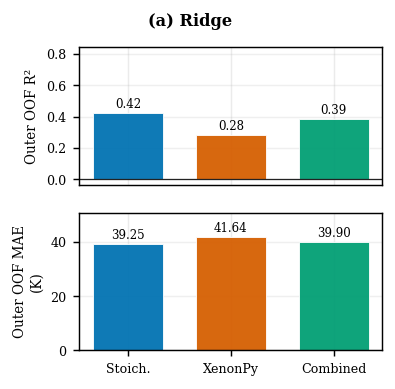

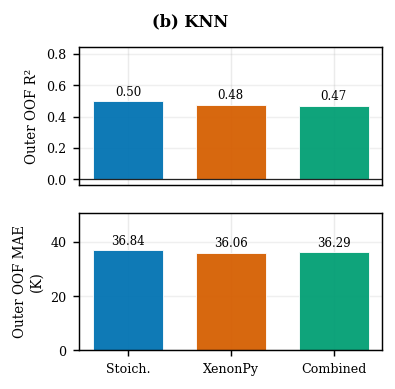

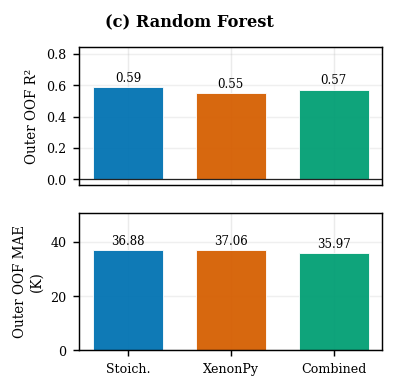

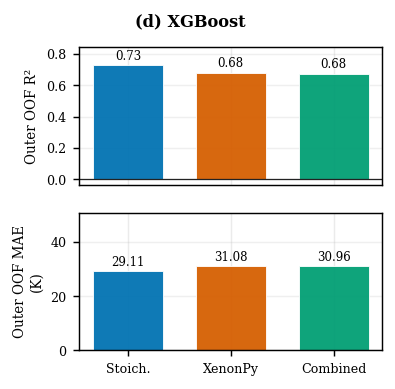

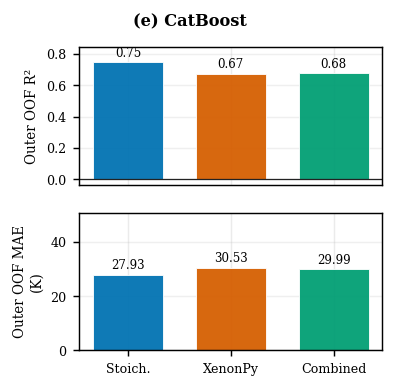

In [15]:
plot_model_comparison(results["summary"])

### График: важность признаков финальных моделей

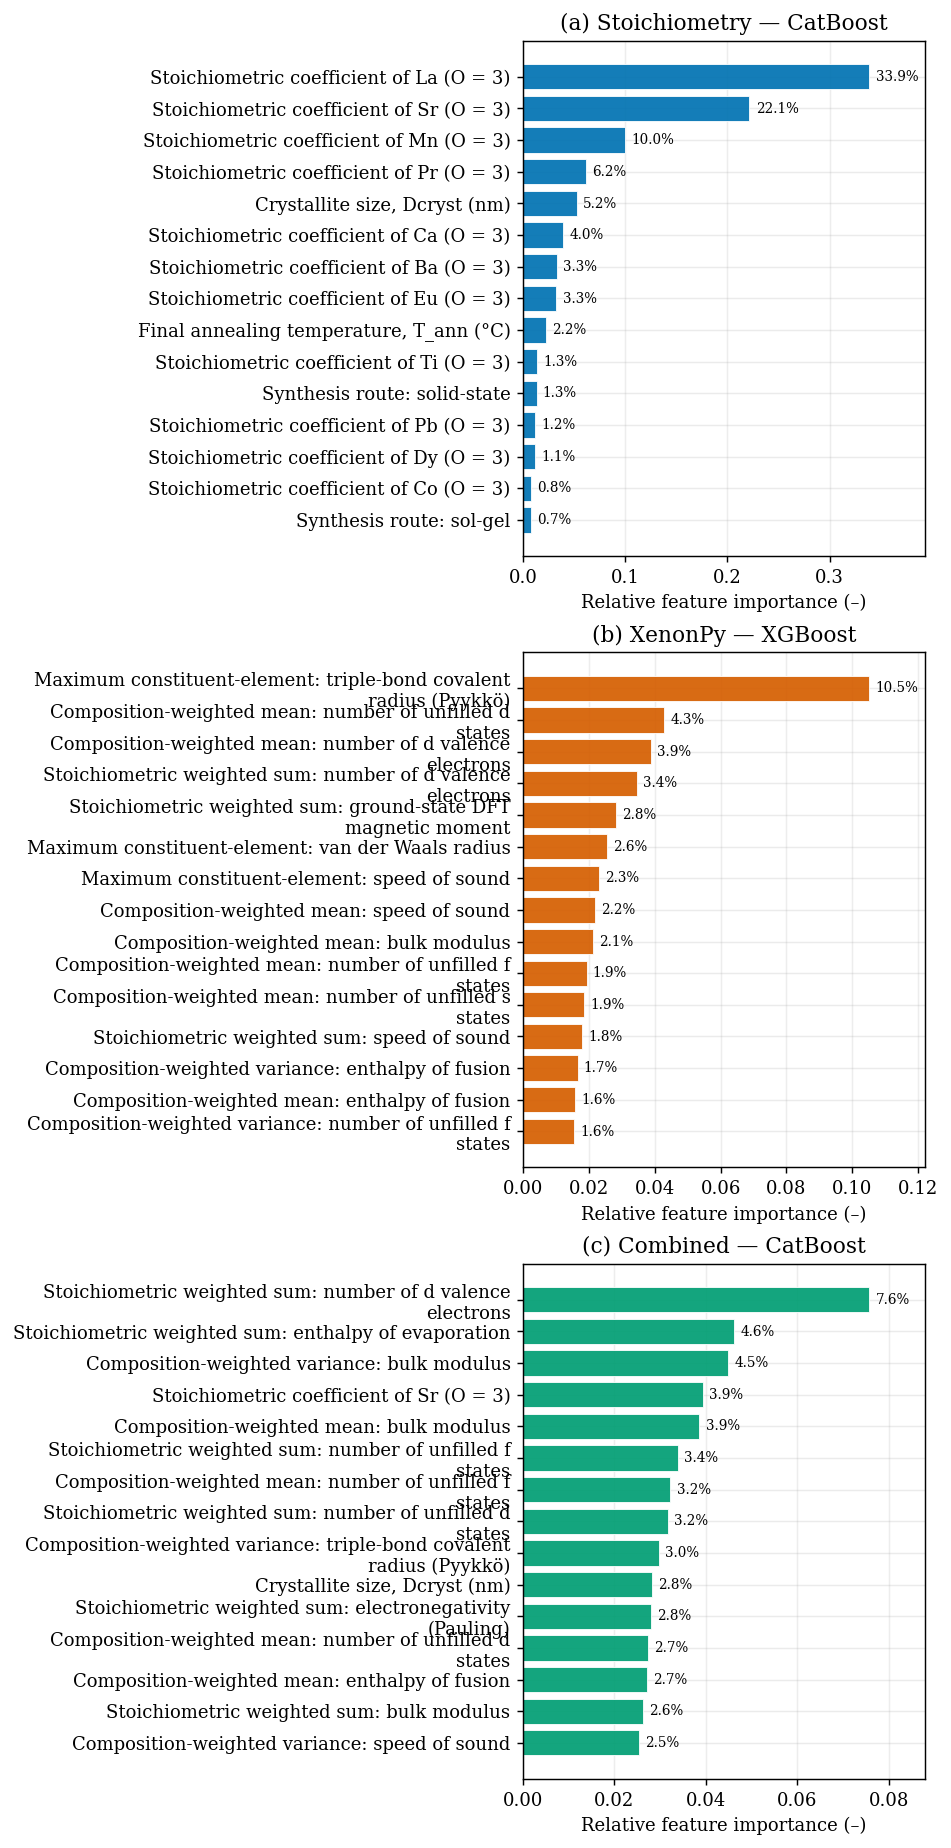

In [16]:
plot_final_feature_importance(results["feature_importance"])

### График: измеренная и предсказанная Tc (цвет — размер кристаллитов)

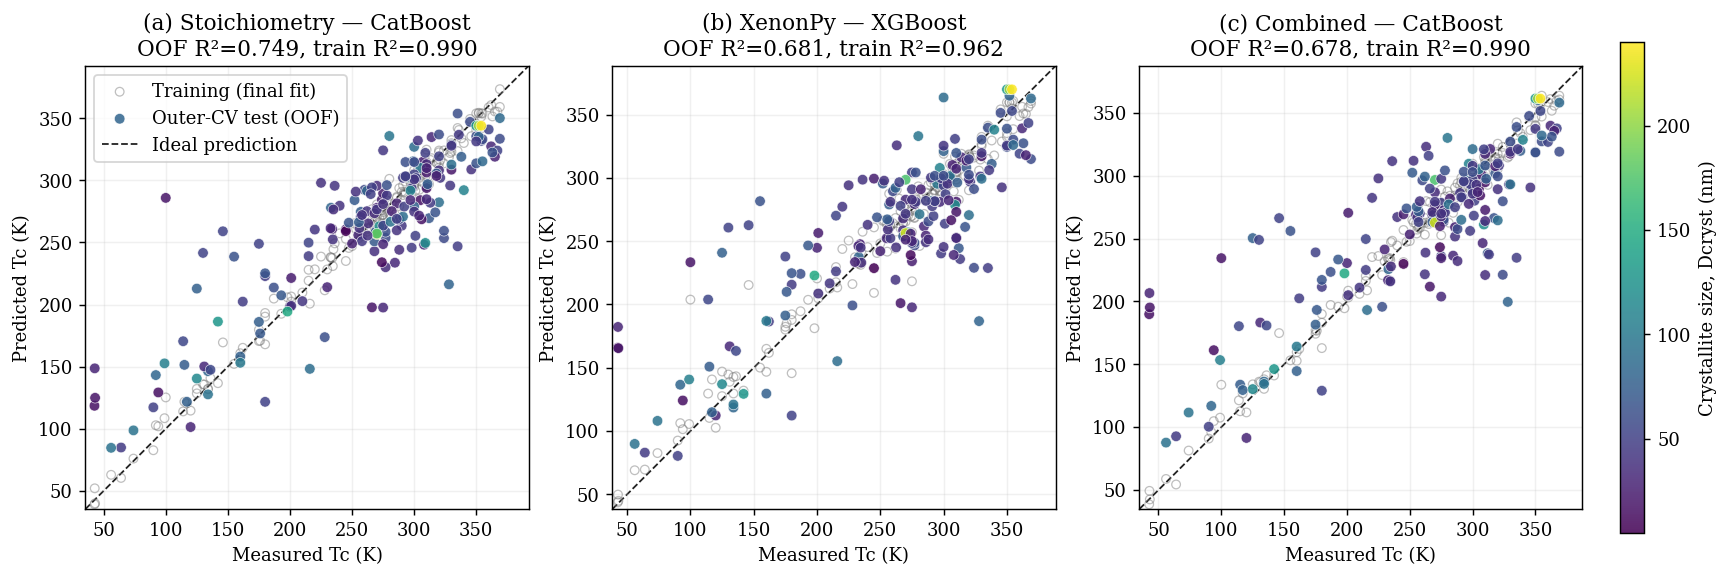

In [17]:
plot_best_parity(
    results["predictions"],
    results["ml_dataset"],
    results["final_models"],
)

### Метрики по диапазонам размера кристаллитов

In [18]:
# Можно задать другой набор или модель:
# metrics_by_size(results, feature_set="Stoichiometry", model="CatBoost")
display(metrics_by_size(results))

Combined | CatBoost (диапазоны с N >= 10)


,Size_nm,N,R2,MAE_K,RMSE_K
0,"[0.0, 20.0)",10,0.379423,65.346340,85.146615
1,"[20.0, 30.0)",19,0.616615,28.428001,45.701353
2,"[30.0, 40.0)",33,0.162678,30.190833,38.594041
3,"[40.0, 50.0)",33,0.715919,24.986130,34.748982
4,"[50.0, 80.0)",60,0.653603,32.029441,44.050902
5,"[80.0, 1000000000.0)",34,0.877526,21.503065,32.621327


## Загрузка результатов после перезапуска kernel

Запустите только если kernel был перезапущен: ячейка читает всё с диска (из папки `OUTPUT_DIRECTORY`), обучение не повторяется.

In [19]:
# results = load_saved_results()

## Установка пакетов (при необходимости)

In [ ]:
%pip install "numpy==1.26.4"
%pip install "xenonpy==0.6.7" rdkit
%pip install pandas matplotlib scikit-learn openpyxl joblib
%pip install pymatgen xgboost catboost plotly